# 43008 Reinforcement Learning -- Assignment 3, Part E: Value-Based Deep Reinforcement Learning on Snake

**The Deadly Triad (project 48): Yue Liu (25211451), Jiahao Liu (14191136), Siqin Jin (26145324)**

**Project**: a controlled study of state representation, reward design and DQN stabilisation on a self-built Snake
environment (8 x 8 and 10 x 10 boards): tabular Q-learning; DQN on an 11-feature vector (observation A, MLP) or an
8-plane grid (observation B8, CNN); the discount factor; the replay buffer and the target network; Double DQN, Dueling
and prioritised replay; four reward designs (R0 sparse, R1 step penalty, R2 potential-based shaping, R3 naive distance
bonus) and a reward-hacking probe; random, BFS-greedy and Hamiltonian-cycle reference players. Every configuration is
trained with five seeds, the seed is the unit of replication and every interval is a 95 % Student-t interval over seeds.

**What this notebook does**: it regenerates every table and figure of the report from the training logs.
`snake_rl.analysis.report` reads the run directories under `runs/` (per seed: `config.yaml`, `metrics.csv`,
`final_eval.json`), aggregates the seeds of every configuration and writes `runs/report/`: tables as Markdown, figures
as PNG, `index.md` and `manifest.json`. No number of the report is typed by hand; these files are the numbers.

**Training logs**: `runs/` is not in the repository (about 1 GB with checkpoints; the logs alone are about 12 MB,
4 MB zipped). Three ways to get them into this session: (1) upload `runs_logs.zip`, made with
`python scripts/export_logs.py` on the machine that trained, when the cell of Section 2 asks for it; (2) set `LOGS_URL`
in that cell to a link to the zip (for example a GitHub release asset); (3) run the notebook inside a checkout that
already has `runs/`.

**Behaviour analyses** (visit heat-maps, loop statistics, recordings of the longest loops) need the weights of a run,
which the zip does not carry; Section 5 runs one when a `model.pt` is present, and the composite heat-map figures of
Section 4.3 need the saved analyses (`python scripts/export_logs.py --include-behaviour`).

### 1. Repository and Imports

In [1]:
# Clone the repository and install the package when running on Google Colab; a local checkout is used as it is
import os
import subprocess
import sys

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/Cureeeeeeee/Value-Based-Deep-Reinforcement-Learning-on-Snake.git"

if not os.path.isdir("snake_rl"):
    if not os.path.isdir("snake-rl"):
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, "snake-rl"], check=True)
    os.chdir("snake-rl")
if IN_COLAB:
    %pip install -q -e .
print("working directory:", os.getcwd())

working directory: C:\STUDY\Reinforcement_Learning\assignment\Ass3\snake-rl


In [2]:
import glob
import json
import urllib.request
import zipfile

import numpy as np
import torch
from IPython.display import Image, Markdown, display

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"python {sys.version.split()[0]}  torch {torch.__version__}  numpy {np.__version__}  device {DEVICE}")

python 3.13.7  torch 2.11.0+cu128  numpy 2.5.3  device cuda


### 2. Training Logs

In [3]:
# Training logs: the local runs/ directory, or runs_logs.zip (scripts/export_logs.py) from LOGS_URL or the Colab upload dialog
LOGS_URL = ""               # link to runs_logs.zip; empty: upload it on Colab, or use the local runs/
LOGS_ZIP = "runs_logs.zip"


def experiment_dirs():
    return sorted(d for d in glob.glob("runs/*/") if glob.glob(os.path.join(d, "*", "final_eval.json")))


if not experiment_dirs():
    if LOGS_URL:
        urllib.request.urlretrieve(LOGS_URL, LOGS_ZIP)
    elif IN_COLAB and not os.path.exists(LOGS_ZIP):
        from google.colab import files

        LOGS_ZIP = next(iter(files.upload()))
    elif not os.path.exists(LOGS_ZIP):
        raise FileNotFoundError("no runs/ and no runs_logs.zip: set LOGS_URL or copy the zip next to this notebook")
    with zipfile.ZipFile(LOGS_ZIP) as zf:
        zf.extractall(".")  # entries are runs/<experiment>/<seed>/<file>

print(len(experiment_dirs()), "experiment directories with finished runs under runs/")

64 experiment directories with finished runs under runs/


### 3. Experiment Matrix

The 64 configurations of the study are defined in `snake_rl/analysis/matrix.py`; the status table lists the finished
seeds of every row and checks each run's recorded `config.yaml` against the row that launched it.

In [4]:
# Finished seeds per configuration, and every run's config.yaml checked against the matrix
!{sys.executable} -m snake_rl.analysis.matrix --status

| experiment | board | group | config | overrides | finished | aborted | unfinished | configuration |
|---|---|---|---|---|---|---|---|---|
| tabular_q_W8 | 8x8 | tabular | configs/tabular_q_8x8.yaml | - | 5/5 | 0 | 0 | ok |
| tabular_q_W8_gamma0 | 8x8 | tabular | configs/tabular_q_8x8.yaml | agent.gamma=0.0 | 5/5 | 0 | 0 | ok |
| dqn_A_W8 | 8x8 | main | configs/dqn_A_8x8.yaml | - | 5/5 | 0 | 0 | ok |
| dqn_B8_W8 | 8x8 | main | configs/dqn_B_8x8.yaml | - | 5/5 | 0 | 0 | ok |
| dqn_B3_W8 | 8x8 | obs | configs/dqn_B_8x8.yaml | env.obs.age_plane=false env.obs.heading_planes=false | 5/5 | 0 | 0 | ok |
| dqn_B7_W8 | 8x8 | obs | configs/dqn_B_8x8.yaml | env.obs.age_plane=false | 5/5 | 0 | 0 | ok |
| dqn_A_W8_gamma099 | 8x8 | gamma | configs/dqn_A_8x8.yaml | agent.gamma=0.99 | 5/5 | 0 | 0 | ok |
| dqn_B8_W8_gamma099 | 8x8 | gamma | configs/dqn_B_8x8.yaml | agent.gamma=0.99 | 5/5 | 0 | 0 | ok |
| dqn_A_W8_noreplay | 8x8 | components | configs/dqn_A_8x8.yaml | agent.replay=false | 5/5 | 0 | 0 |

### 4. Tables and Figures of the Report

#### 4.1 Build from the logs

In [5]:
# Every table and figure of the report; items whose experiments are missing are skipped and listed in runs/report/index.md
!{sys.executable} -m snake_rl.analysis.report --runs-dir runs --out-dir runs/report

partC_W8: table, curve
partC_W10: table, curve
obs_W8: table, curve
obs_W10: table, curve
gamma_W8: table, curve, values
gamma_W10: table, curve, values
components_A_W8: table, curve
components_B8_W8: table, curve
components_A_W10: table, curve
components_B8_W10: table, curve
budget_W8: table, curve
budget_W10: table, curve
capacity_W8: table, curve
variants_A_W8: table, curve
variants_B8_W8: table, curve
values_double_A_W8: values
values_double_B8_W8: values
reward_A_W8_gamma09: table, curve, causes
reward_A_W8_gamma099: table, curve, causes
reward_B8_W8_gamma09: table, curve, causes
reward_B8_W8_gamma099: table, curve, causes
reward_B8_W10_gamma099: table, curve, causes
probe_W8: table, curve, causes
summary_W8: table
summary_W10: table
runs\report\index.md


#### 4.2 Display

One item of `manifest.json` per table and figure, with the experiments and seeds behind it; the `last-5` column of a
table is the mean of each agent's last five evaluations.

code 96abe54+dirty | last-k column: 5 | 25 items


##### partC_W8

8x8: tabular Q-learning and DQN on observation A (5 seeds, 95% t CI)

| label | seeds | episodes | score mean +- 95% CI | CI over | median | max | mean steps | wall | self | starve | win | last-5 evals mean +- 95% CI |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| random | 1 | 100 | 0.23 +- 0.10 | episodes | 0.0 | 2 | 13.2 | 0.98 | 0.02 | 0.00 | 0.00 | n/a |
| BFS greedy | 1 | 100 | 23.07 +- 1.13 | episodes | 23.0 | 38 | 151.4 | 0.35 | 0.65 | 0.00 | 0.00 | n/a |
| Hamiltonian | 1 | 100 | 61.00 +- 0.00 | episodes | 61.0 | 61 | 985.9 | 0.00 | 0.00 | 0.00 | 1.00 | n/a |
| tabular Q | 5 | 100 | 15.67 +- 0.87 | seeds | 15.5 | 34 | 102.0 | 0.19 | 0.81 | 0.00 | 0.00 | 15.67 +- 0.40 |
| tabular Q, gamma 0 | 5 | 100 | 16.07 +- 0.10 | seeds | 16.0 | 27 | 151.5 | 0.07 | 0.93 | 0.00 | 0.00 | 16.07 +- 0.10 |
| A (MLP) | 5 | 100 | 16.11 +- 0.88 | seeds | 16.0 | 35 | 104.9 | 0.21 | 0.79 | 0.00 | 0.00 | 16.07 +- 0.64 |


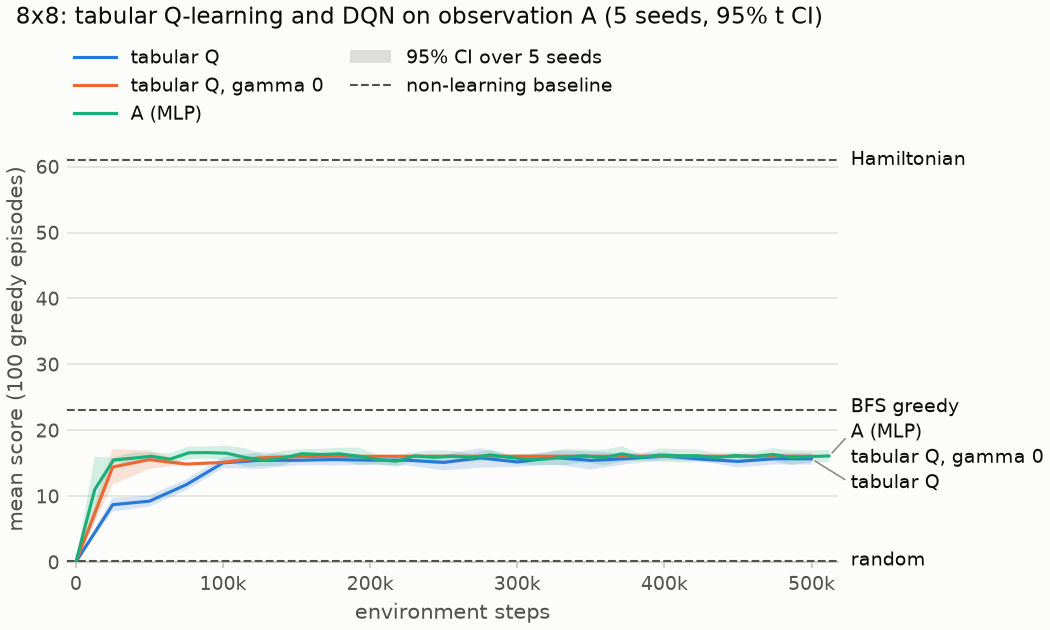

##### partC_W10

10x10: tabular Q-learning and DQN on observation A (5 seeds, 95% t CI)

| label | seeds | episodes | score mean +- 95% CI | CI over | median | max | mean steps | wall | self | starve | win | last-5 evals mean +- 95% CI |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| random | 1 | 100 | 0.18 +- 0.08 | episodes | 0.0 | 2 | 23.0 | 0.98 | 0.01 | 0.01 | 0.00 | n/a |
| BFS greedy | 1 | 100 | 30.61 +- 1.60 | episodes | 31.0 | 58 | 255.8 | 0.16 | 0.84 | 0.00 | 0.00 | n/a |
| Hamiltonian | 1 | 100 | 97.00 +- 0.00 | episodes | 97.0 | 97 | 2409.7 | 0.00 | 0.00 | 0.00 | 1.00 | n/a |
| tabular Q | 5 | 100 | 18.51 +- 1.10 | seeds | 18.0 | 40 | 150.6 | 0.10 | 0.90 | 0.00 | 0.00 | 18.14 +- 0.29 |
| tabular Q, gamma 0 | 5 | 100 | 19.69 +- 0.00 | seeds | 20.0 | 34 | 239.2 | 0.04 | 0.96 | 0.00 | 0.00 | 19.69 +- 0.00 |
| A (MLP) | 5 | 100 | 20.29 +- 1.55 | seeds | 20.0 | 41 | 167.8 | 0.16 | 0.84 | 0.00 | 0.00 | 20.44 +- 1.41 |


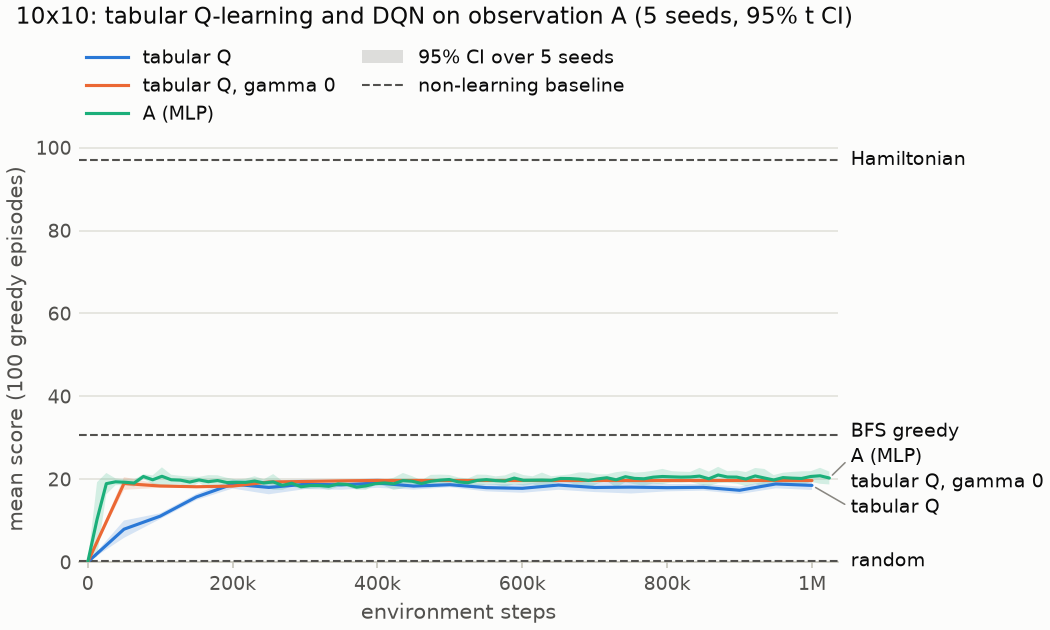

##### obs_W8

8x8: state representation (5 seeds, 95% t CI)

| label | seeds | episodes | score mean +- 95% CI | CI over | median | max | mean steps | wall | self | starve | win | last-5 evals mean +- 95% CI |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| BFS greedy | 1 | 100 | 23.07 +- 1.13 | episodes | 23.0 | 38 | 151.4 | 0.35 | 0.65 | 0.00 | 0.00 | n/a |
| A (MLP) | 5 | 100 | 16.11 +- 0.88 | seeds | 16.0 | 35 | 104.9 | 0.21 | 0.79 | 0.00 | 0.00 | 16.07 +- 0.64 |
| B3 (CNN) | 5 | 100 | 13.54 +- 0.61 | seeds | 14.0 | 26 | 100.6 | 0.18 | 0.82 | 0.01 | 0.00 | 13.48 +- 0.36 |
| B7 (CNN) | 5 | 100 | 18.18 +- 0.85 | seeds | 18.0 | 30 | 135.1 | 0.08 | 0.92 | 0.00 | 0.00 | 17.93 +- 0.81 |
| B8 (CNN) | 5 | 100 | 17.81 +- 0.90 | seeds | 18.0 | 32 | 131.4 | 0.05 | 0.95 | 0.00 | 0.00 | 17.63 +- 0.28 |


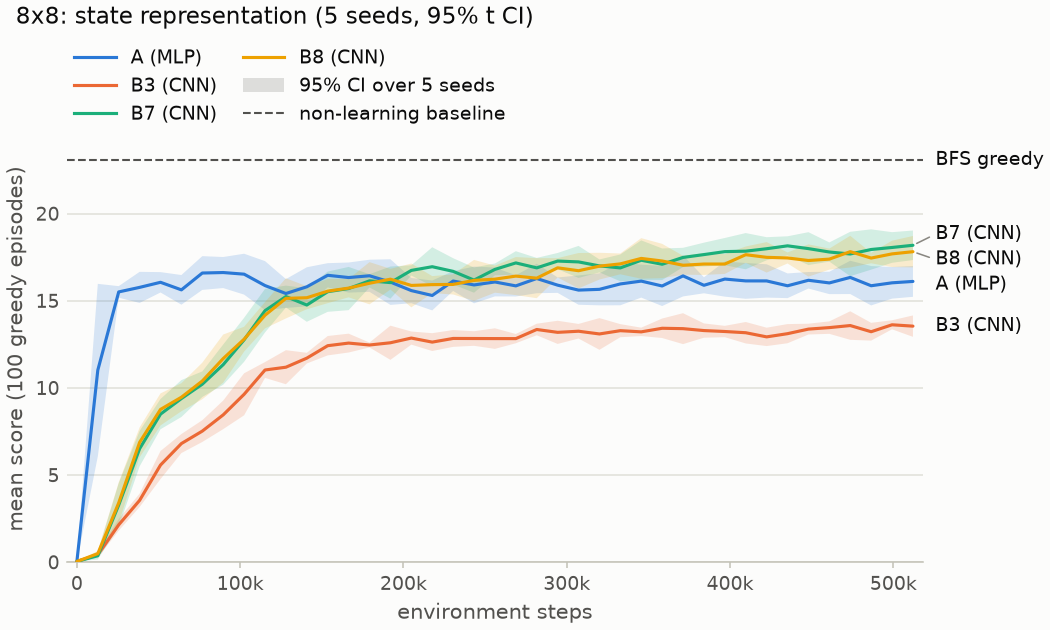

##### obs_W10

10x10: state representation (5 seeds, 95% t CI)

| label | seeds | episodes | score mean +- 95% CI | CI over | median | max | mean steps | wall | self | starve | win | last-5 evals mean +- 95% CI |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| BFS greedy | 1 | 100 | 30.61 +- 1.60 | episodes | 31.0 | 58 | 255.8 | 0.16 | 0.84 | 0.00 | 0.00 | n/a |
| A (MLP) | 5 | 100 | 20.29 +- 1.55 | seeds | 20.0 | 41 | 167.8 | 0.16 | 0.84 | 0.00 | 0.00 | 20.44 +- 1.41 |
| B3 (CNN) | 5 | 100 | 16.12 +- 0.25 | seeds | 16.0 | 32 | 150.4 | 0.16 | 0.84 | 0.00 | 0.00 | 15.81 +- 0.33 |
| B7 (CNN) | 5 | 100 | 21.84 +- 0.74 | seeds | 22.0 | 38 | 203.5 | 0.07 | 0.93 | 0.00 | 0.00 | 21.49 +- 0.43 |
| B8 (CNN) | 5 | 100 | 20.69 +- 0.52 | seeds | 21.0 | 35 | 187.6 | 0.07 | 0.93 | 0.00 | 0.00 | 20.85 +- 0.59 |


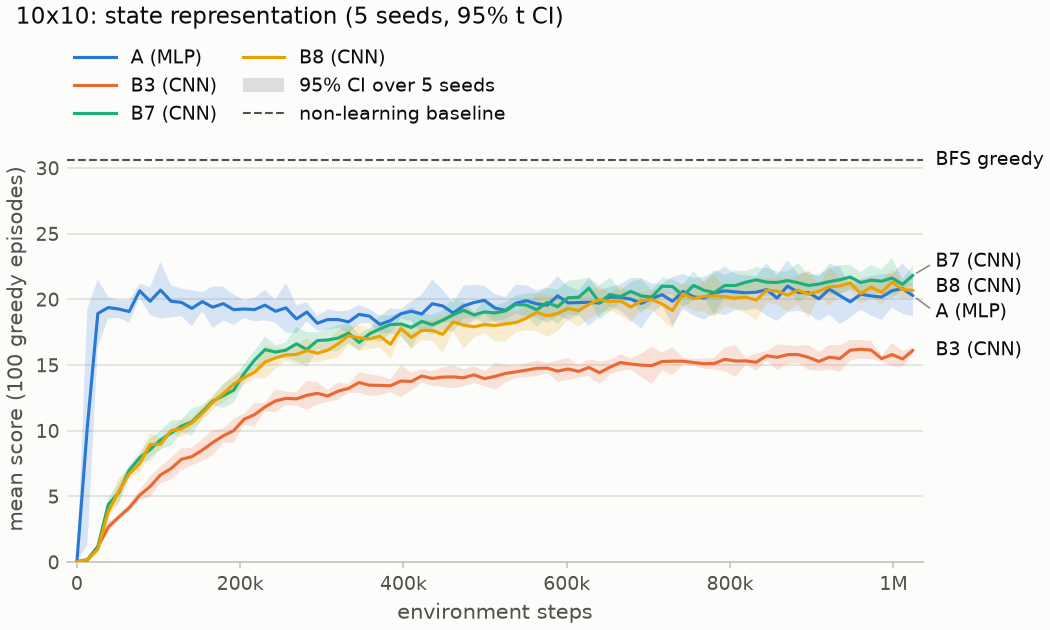

##### gamma_W8

8x8: discount factor x representation (5 seeds, 95% t CI)

| label | seeds | episodes | score mean +- 95% CI | CI over | median | max | mean steps | wall | self | starve | win | last-5 evals mean +- 95% CI |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| BFS greedy | 1 | 100 | 23.07 +- 1.13 | episodes | 23.0 | 38 | 151.4 | 0.35 | 0.65 | 0.00 | 0.00 | n/a |
| A (MLP) | 5 | 100 | 16.11 +- 0.88 | seeds | 16.0 | 35 | 104.9 | 0.21 | 0.79 | 0.00 | 0.00 | 16.07 +- 0.64 |
| A, gamma 0.99 | 5 | 100 | 15.91 +- 0.60 | seeds | 16.0 | 35 | 103.0 | 0.20 | 0.80 | 0.00 | 0.00 | 16.04 +- 0.20 |
| B8 (CNN) | 5 | 100 | 17.81 +- 0.90 | seeds | 18.0 | 32 | 131.4 | 0.05 | 0.95 | 0.00 | 0.00 | 17.63 +- 0.28 |
| B8, gamma 0.99 | 5 | 100 | 22.72 +- 1.04 | seeds | 23.0 | 34 | 220.3 | 0.03 | 0.96 | 0.01 | 0.00 | 22.39 +- 0.55 |


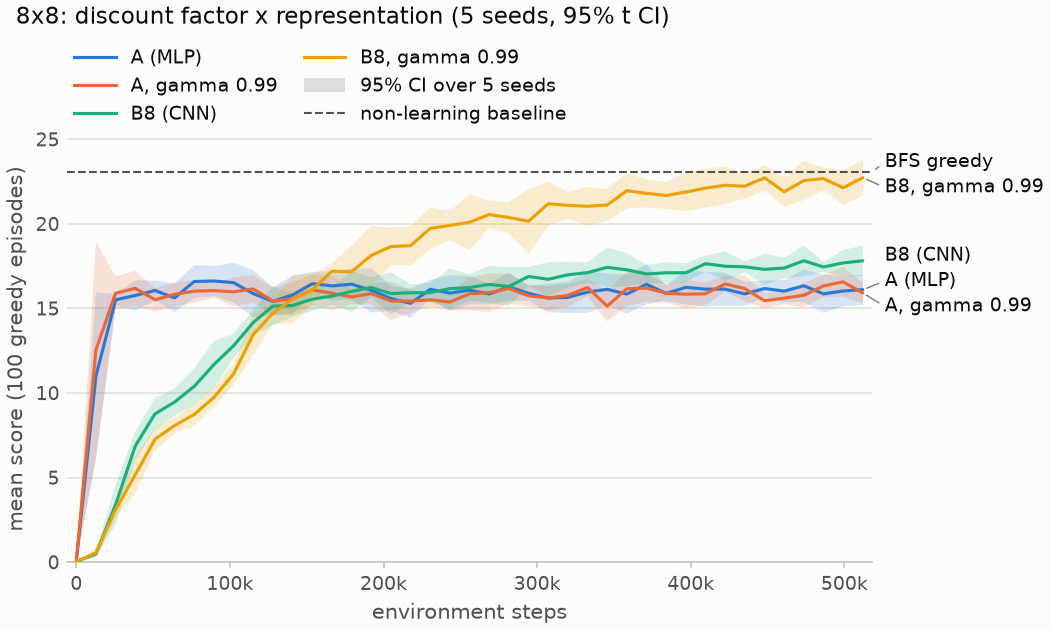

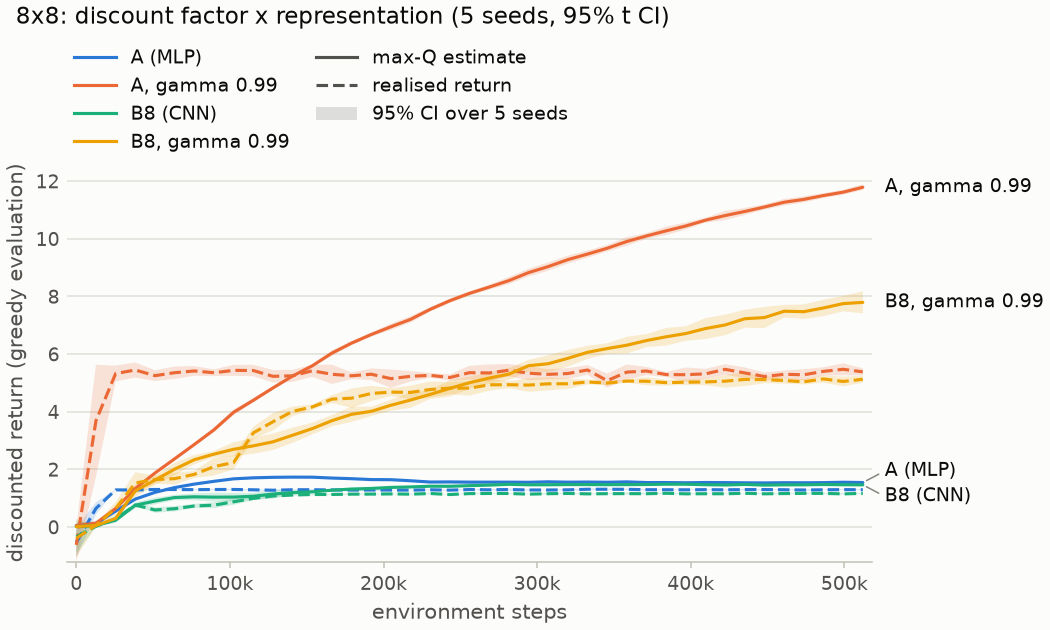

##### gamma_W10

10x10: discount factor x representation (5 seeds, 95% t CI)

| label | seeds | episodes | score mean +- 95% CI | CI over | median | max | mean steps | wall | self | starve | win | last-5 evals mean +- 95% CI |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| BFS greedy | 1 | 100 | 30.61 +- 1.60 | episodes | 31.0 | 58 | 255.8 | 0.16 | 0.84 | 0.00 | 0.00 | n/a |
| A (MLP) | 5 | 100 | 20.29 +- 1.55 | seeds | 20.0 | 41 | 167.8 | 0.16 | 0.84 | 0.00 | 0.00 | 20.44 +- 1.41 |
| B8 (CNN) | 5 | 100 | 20.69 +- 0.52 | seeds | 21.0 | 35 | 187.6 | 0.07 | 0.93 | 0.00 | 0.00 | 20.85 +- 0.59 |
| B8, gamma 0.99 | 5 | 100 | 25.72 +- 0.83 | seeds | 26.0 | 42 | 333.7 | 0.03 | 0.94 | 0.03 | 0.00 | 25.46 +- 0.40 |


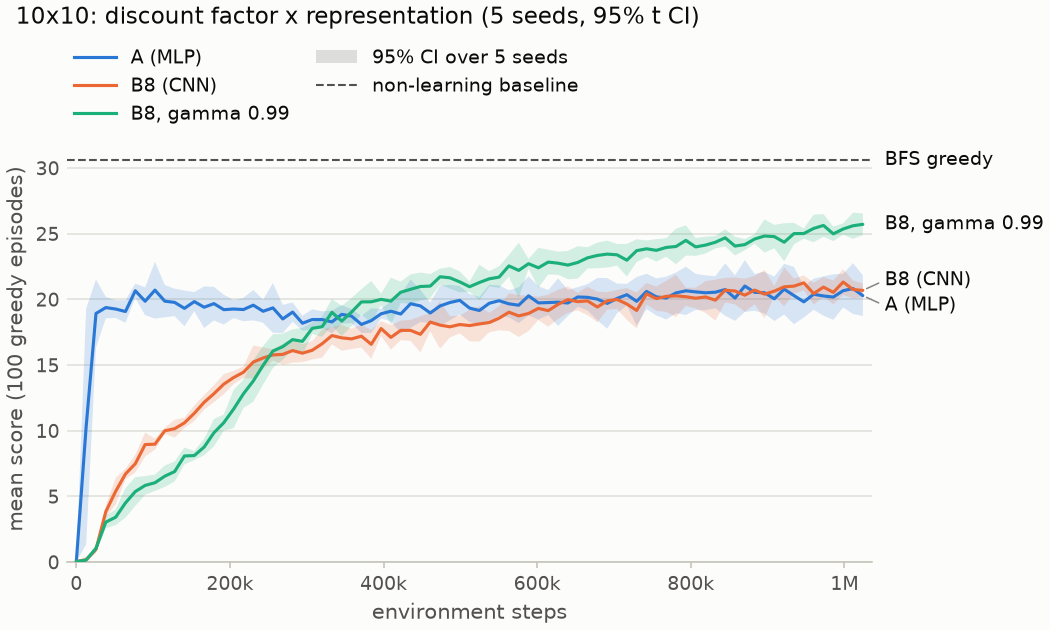

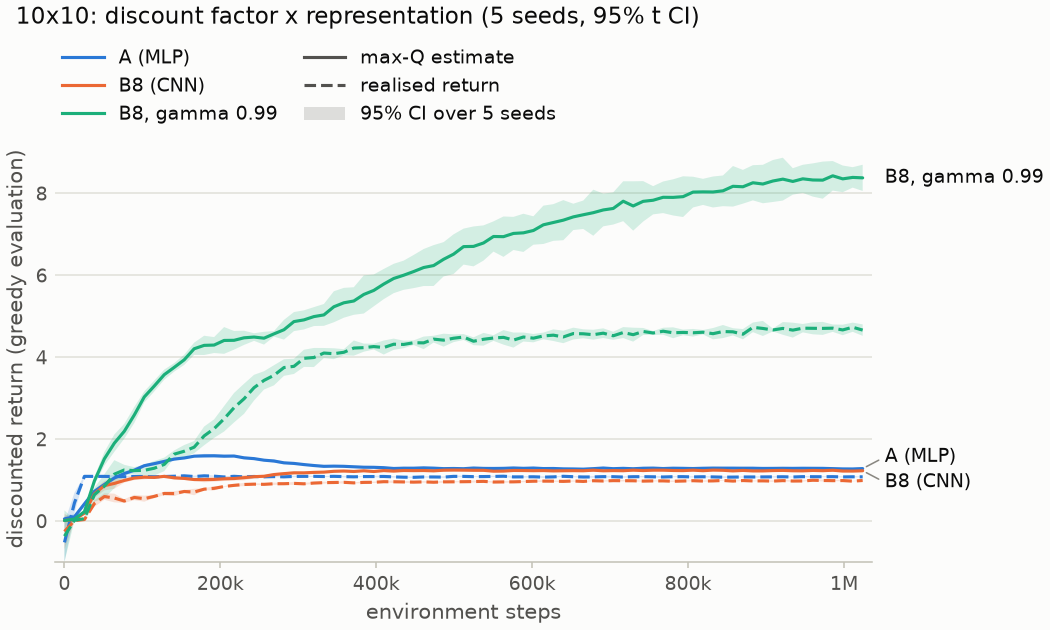

##### components_A_W8

8x8, observation A: replay and target network (5 seeds, 95% t CI)

| label | seeds | episodes | score mean +- 95% CI | CI over | median | max | mean steps | wall | self | starve | win | last-5 evals mean +- 95% CI |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| A (MLP) | 5 | 100 | 16.11 +- 0.88 | seeds | 16.0 | 35 | 104.9 | 0.21 | 0.79 | 0.00 | 0.00 | 16.07 +- 0.64 |
| A, no replay | 5 | 100 | 15.39 +- 0.80 | seeds | 15.0 | 35 | 99.2 | 0.01 | 0.99 | 0.00 | 0.00 | 15.68 +- 0.71 |
| A, no replay, target 31 | 5 | 100 | 15.54 +- 0.68 | seeds | 15.0 | 31 | 100.0 | 0.02 | 0.98 | 0.00 | 0.00 | 15.24 +- 0.49 |
| A, no target | 5 | 100 | 16.61 +- 1.04 | seeds | 16.0 | 33 | 110.5 | 0.26 | 0.74 | 0.00 | 0.00 | 16.59 +- 0.60 |
| A, no replay, no target | 5 | 100 | 15.43 +- 0.81 | seeds | 15.0 | 31 | 100.0 | 0.01 | 0.99 | 0.00 | 0.00 | 15.43 +- 0.47 |


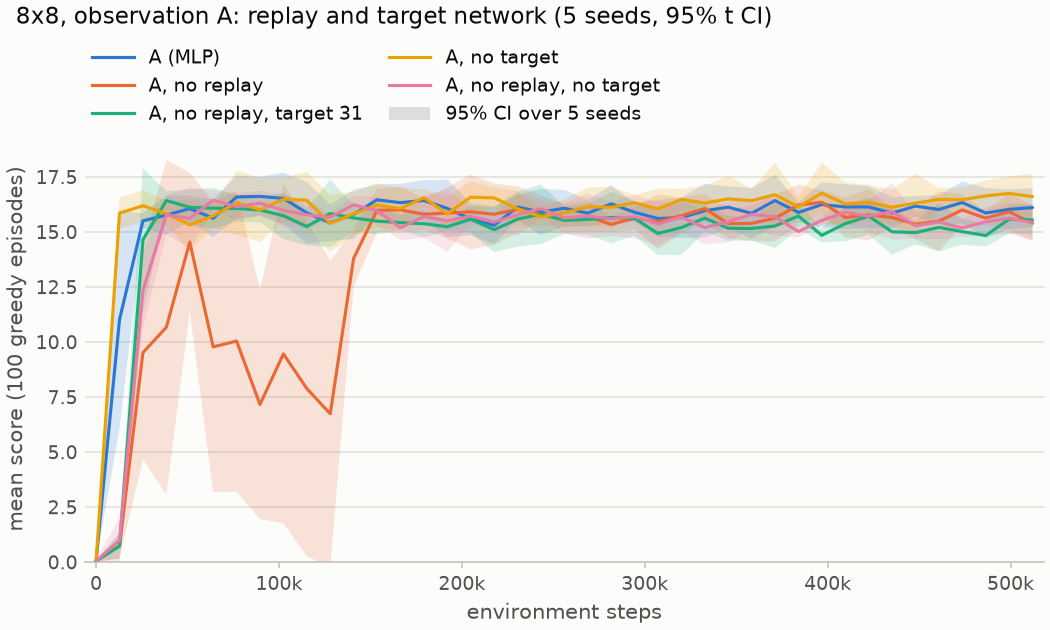

##### components_B8_W8

8x8, observation B8: replay and target network (5 seeds, 95% t CI)

| label | seeds | episodes | score mean +- 95% CI | CI over | median | max | mean steps | wall | self | starve | win | last-5 evals mean +- 95% CI |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| B8 (CNN) | 5 | 100 | 17.81 +- 0.90 | seeds | 18.0 | 32 | 131.4 | 0.05 | 0.95 | 0.00 | 0.00 | 17.63 +- 0.28 |
| B8, no replay | 5 | 100 | 8.55 +- 3.09 | seeds | 9.0 | 26 | 126.9 | 0.00 | 0.58 | 0.42 | 0.00 | 8.38 +- 3.32 |
| B8, no replay, target 31 | 5 | 100 | 14.03 +- 1.39 | seeds | 14.0 | 28 | 100.5 | 0.00 | 0.98 | 0.02 | 0.00 | 13.98 +- 0.77 |
| B8, no target | 5 | 100 | 18.01 +- 0.67 | seeds | 18.0 | 30 | 132.3 | 0.06 | 0.94 | 0.00 | 0.00 | 18.16 +- 0.63 |
| B8, no replay, no target | 5 | 100 | 13.90 +- 0.84 | seeds | 14.0 | 27 | 99.2 | 0.01 | 0.99 | 0.01 | 0.00 | 13.70 +- 0.65 |


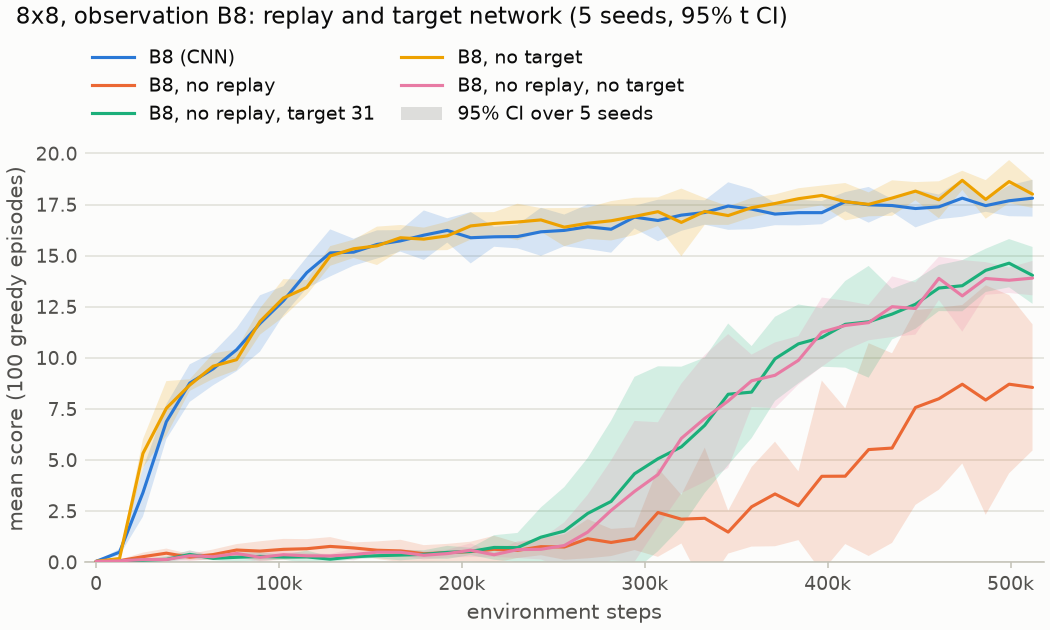

##### components_A_W10

10x10, observation A: replay and target network (5 seeds, 95% t CI)

| label | seeds | episodes | score mean +- 95% CI | CI over | median | max | mean steps | wall | self | starve | win | last-5 evals mean +- 95% CI |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| A (MLP) | 5 | 100 | 20.29 +- 1.55 | seeds | 20.0 | 41 | 167.8 | 0.16 | 0.84 | 0.00 | 0.00 | 20.44 +- 1.41 |
| A, no replay, target 31 | 5 | 100 | 18.22 +- 0.47 | seeds | 18.0 | 39 | 146.0 | 0.02 | 0.98 | 0.00 | 0.00 | 18.33 +- 0.20 |
| A, no target | 5 | 100 | 20.73 +- 1.77 | seeds | 20.0 | 46 | 173.1 | 0.16 | 0.84 | 0.00 | 0.00 | 20.56 +- 1.22 |


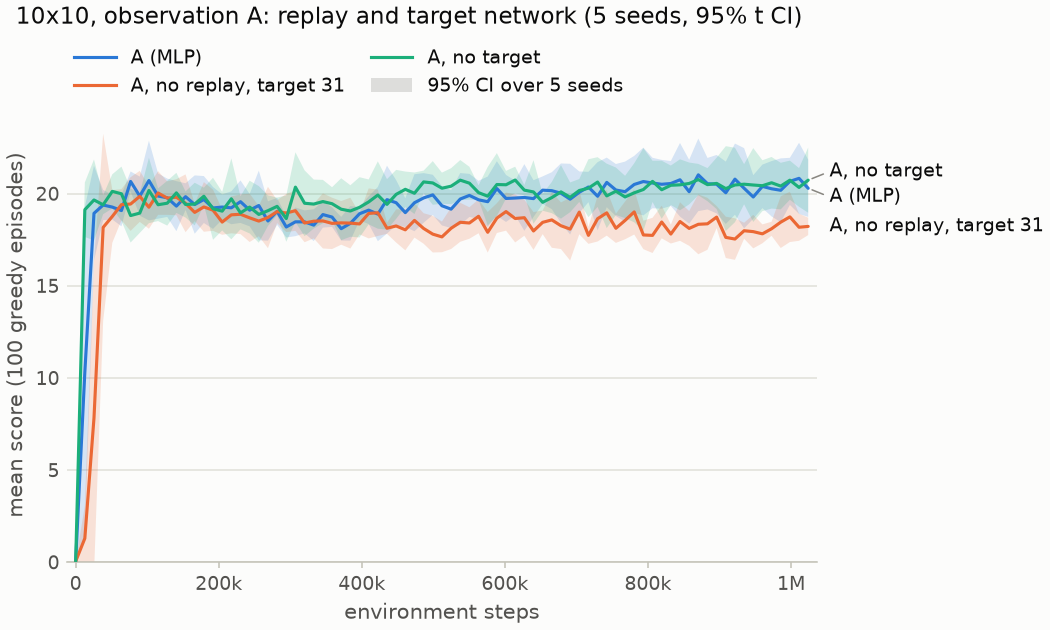

##### components_B8_W10

10x10, observation B8: replay and target network (5 seeds, 95% t CI)

| label | seeds | episodes | score mean +- 95% CI | CI over | median | max | mean steps | wall | self | starve | win | last-5 evals mean +- 95% CI |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| B8 (CNN) | 5 | 100 | 20.69 +- 0.52 | seeds | 21.0 | 35 | 187.6 | 0.07 | 0.93 | 0.00 | 0.00 | 20.85 +- 0.59 |
| B8, no replay | 5 | 100 | 16.60 +- 2.33 | seeds | 17.0 | 33 | 183.8 | 0.00 | 0.89 | 0.11 | 0.00 | 16.03 +- 2.81 |
| B8, no replay, target 31 | 5 | 100 | 21.70 +- 1.07 | seeds | 22.0 | 40 | 188.7 | 0.01 | 0.99 | 0.00 | 0.00 | 20.67 +- 0.63 |
| B8, no target | 5 | 100 | 21.03 +- 0.55 | seeds | 21.0 | 36 | 190.1 | 0.08 | 0.92 | 0.00 | 0.00 | 21.45 +- 0.40 |


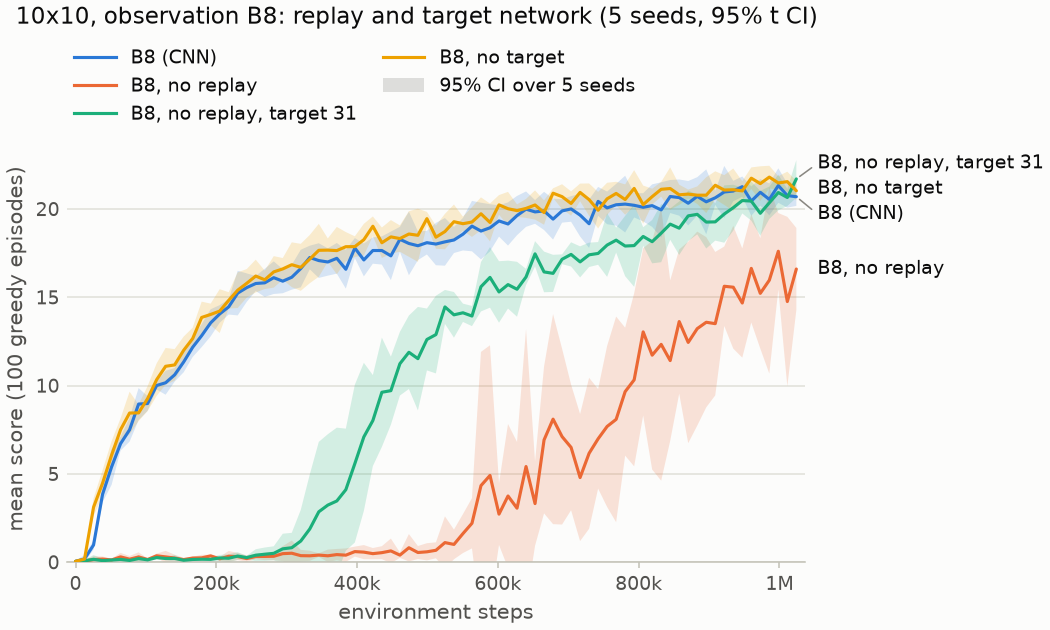

##### budget_W8

8x8: gradient steps per vectorised step (5 seeds, 95% t CI)

| label | seeds | episodes | score mean +- 95% CI | CI over | median | max | mean steps | wall | self | starve | win | last-5 evals mean +- 95% CI |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| A (MLP) | 5 | 100 | 16.11 +- 0.88 | seeds | 16.0 | 35 | 104.9 | 0.21 | 0.79 | 0.00 | 0.00 | 16.07 +- 0.64 |
| A, G=1 | 5 | 100 | 15.02 +- 0.31 | seeds | 15.0 | 36 | 96.7 | 0.02 | 0.98 | 0.00 | 0.00 | 15.38 +- 0.25 |
| A, G=4 | 5 | 100 | 15.39 +- 0.89 | seeds | 15.0 | 31 | 99.7 | 0.11 | 0.89 | 0.00 | 0.00 | 15.55 +- 0.64 |
| A, G=8, batch 1024 | 5 | 100 | 16.00 +- 1.40 | seeds | 16.0 | 38 | 105.1 | 0.17 | 0.83 | 0.00 | 0.00 | 16.02 +- 0.76 |
| B8 (CNN) | 5 | 100 | 17.81 +- 0.90 | seeds | 18.0 | 32 | 131.4 | 0.05 | 0.95 | 0.00 | 0.00 | 17.63 +- 0.28 |
| B8, G=1 | 5 | 100 | 13.73 +- 3.38 | seeds | 14.0 | 30 | 134.1 | 0.00 | 0.88 | 0.12 | 0.00 | 11.83 +- 2.15 |
| B8, G=1, target 31 | 5 | 100 | 16.60 +- 0.82 | seeds | 17.0 | 30 | 119.0 | 0.00 | 0.99 | 0.00 | 0.00 | 16.11 +- 0.65 |


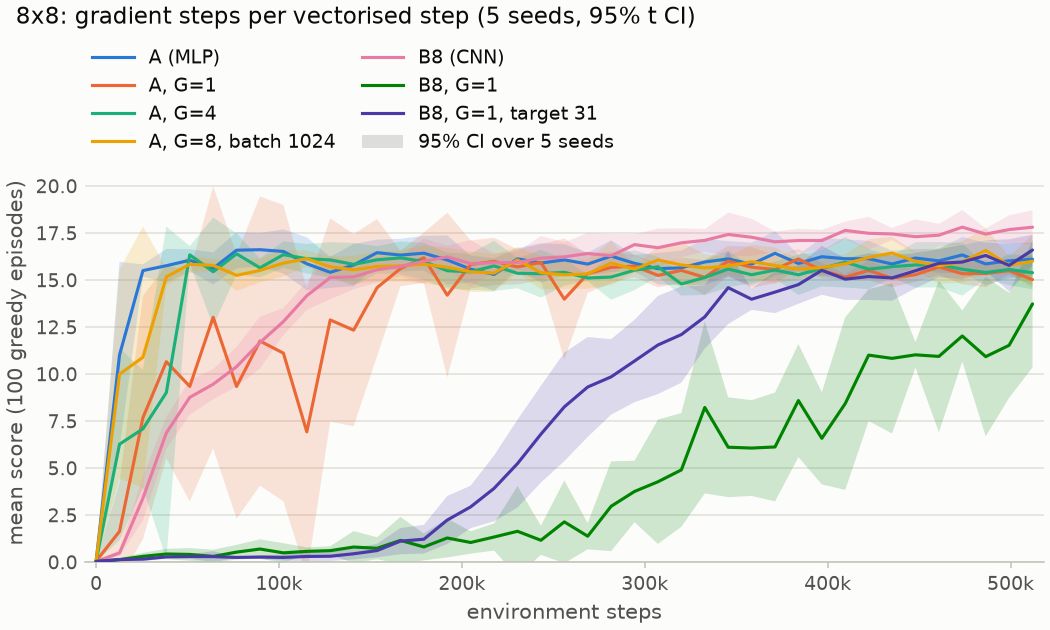

##### budget_W10

10x10: gradient steps per vectorised step (5 seeds, 95% t CI)

| label | seeds | episodes | score mean +- 95% CI | CI over | median | max | mean steps | wall | self | starve | win | last-5 evals mean +- 95% CI |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| B8 (CNN) | 5 | 100 | 20.69 +- 0.52 | seeds | 21.0 | 35 | 187.6 | 0.07 | 0.93 | 0.00 | 0.00 | 20.85 +- 0.59 |
| B8, G=1, target 31 | 5 | 100 | 23.03 +- 1.11 | seeds | 23.0 | 38 | 196.3 | 0.01 | 0.99 | 0.00 | 0.00 | 22.92 +- 0.78 |


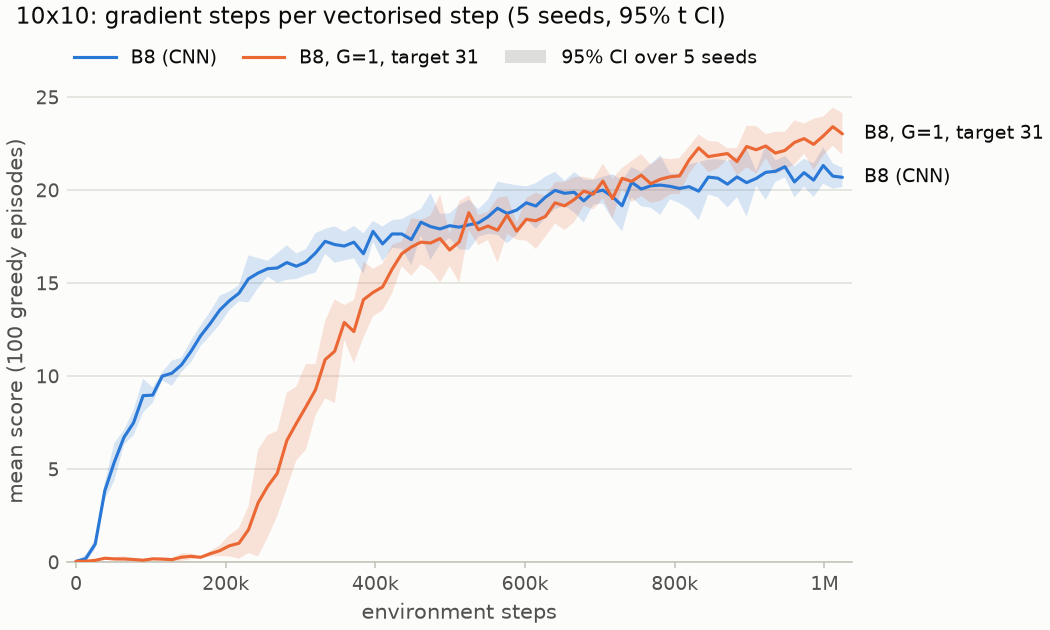

##### capacity_W8

8x8, observation A: network capacity (5 seeds, 95% t CI)

| label | seeds | episodes | score mean +- 95% CI | CI over | median | max | mean steps | wall | self | starve | win | last-5 evals mean +- 95% CI |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| A (MLP) | 5 | 100 | 16.11 +- 0.88 | seeds | 16.0 | 35 | 104.9 | 0.21 | 0.79 | 0.00 | 0.00 | 16.07 +- 0.64 |
| A, hidden 16 | 5 | 100 | 15.60 +- 1.23 | seeds | 15.0 | 36 | 101.7 | 0.01 | 0.99 | 0.00 | 0.00 | 15.79 +- 0.71 |
| A, linear | 5 | 100 | 3.04 +- 5.30 | seeds | 1.0 | 26 | 119.9 | 0.13 | 0.11 | 0.76 | 0.00 | 2.88 +- 4.38 |


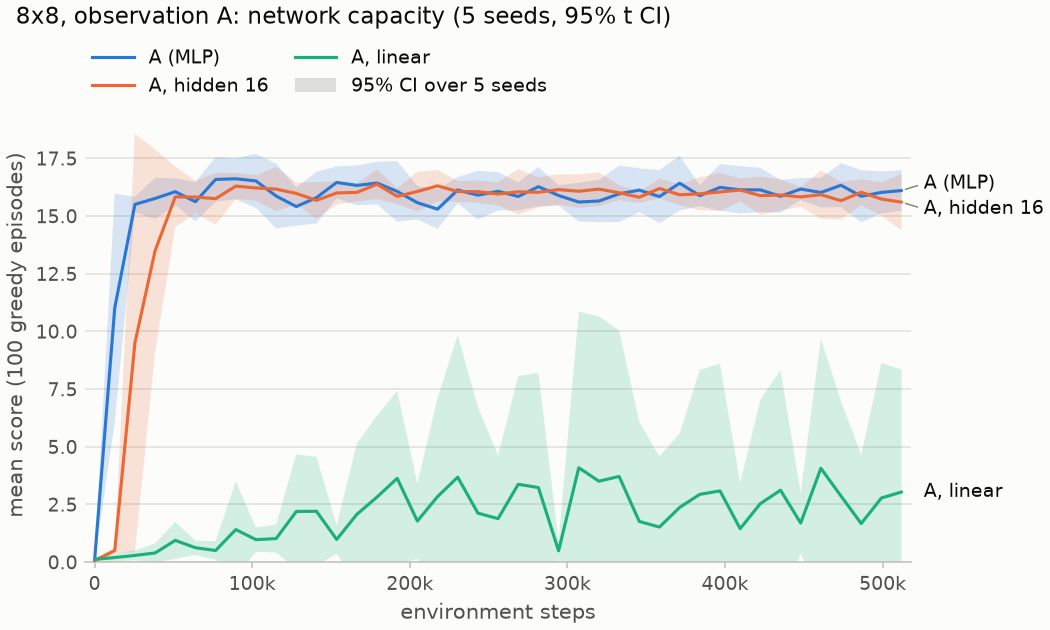

##### variants_A_W8

8x8, observation A: Double, Dueling, PER (5 seeds, 95% t CI)

| label | seeds | episodes | score mean +- 95% CI | CI over | median | max | mean steps | wall | self | starve | win | last-5 evals mean +- 95% CI |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| A (MLP) | 5 | 100 | 16.11 +- 0.88 | seeds | 16.0 | 35 | 104.9 | 0.21 | 0.79 | 0.00 | 0.00 | 16.07 +- 0.64 |
| A, Double | 5 | 100 | 17.21 +- 0.59 | seeds | 17.0 | 36 | 114.3 | 0.31 | 0.69 | 0.00 | 0.00 | 17.14 +- 0.51 |
| A, Dueling | 5 | 100 | 15.45 +- 0.87 | seeds | 15.0 | 33 | 100.9 | 0.20 | 0.80 | 0.00 | 0.00 | 15.66 +- 0.42 |
| A, PER | 5 | 100 | 15.84 +- 0.78 | seeds | 15.0 | 35 | 103.9 | 0.23 | 0.77 | 0.00 | 0.00 | 15.93 +- 0.69 |


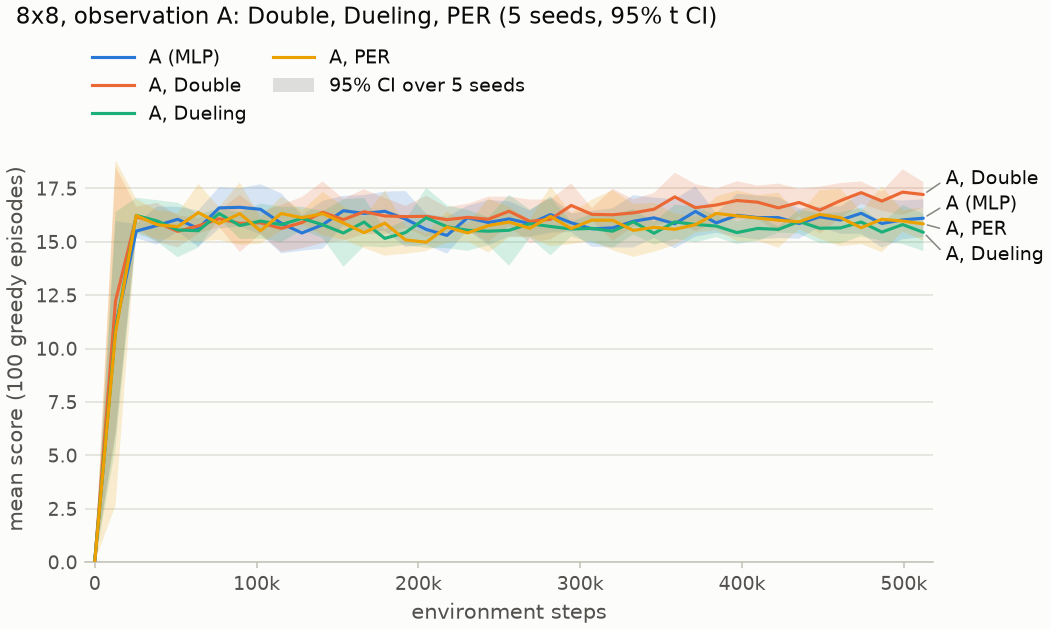

##### variants_B8_W8

8x8, observation B8: Double, Dueling, PER (5 seeds, 95% t CI)

| label | seeds | episodes | score mean +- 95% CI | CI over | median | max | mean steps | wall | self | starve | win | last-5 evals mean +- 95% CI |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| B8 (CNN) | 5 | 100 | 17.81 +- 0.90 | seeds | 18.0 | 32 | 131.4 | 0.05 | 0.95 | 0.00 | 0.00 | 17.63 +- 0.28 |
| B8, Double | 5 | 100 | 17.69 +- 0.56 | seeds | 18.0 | 29 | 131.1 | 0.05 | 0.95 | 0.00 | 0.00 | 17.57 +- 0.30 |
| B8, Dueling | 5 | 100 | 18.09 +- 0.93 | seeds | 18.0 | 30 | 132.3 | 0.02 | 0.98 | 0.00 | 0.00 | 17.83 +- 0.50 |
| B8, PER | 5 | 100 | 17.14 +- 1.08 | seeds | 18.0 | 35 | 123.6 | 0.04 | 0.95 | 0.00 | 0.00 | 17.06 +- 0.26 |


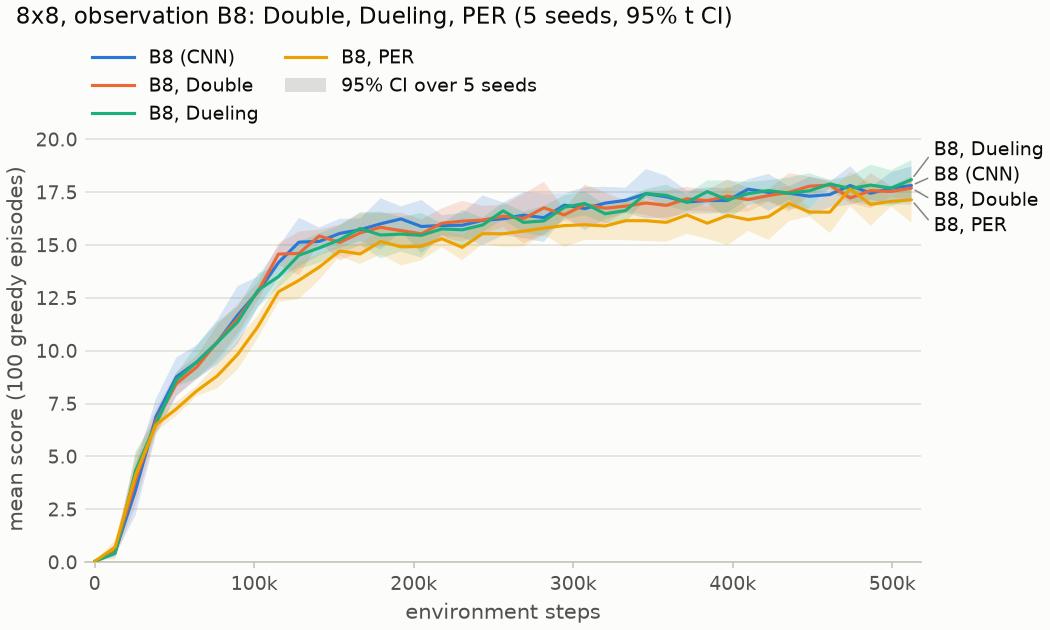

##### values_double_A_W8

8x8, observation A, gamma 0.99: value estimate against realised return (5 seeds, 95% t CI)

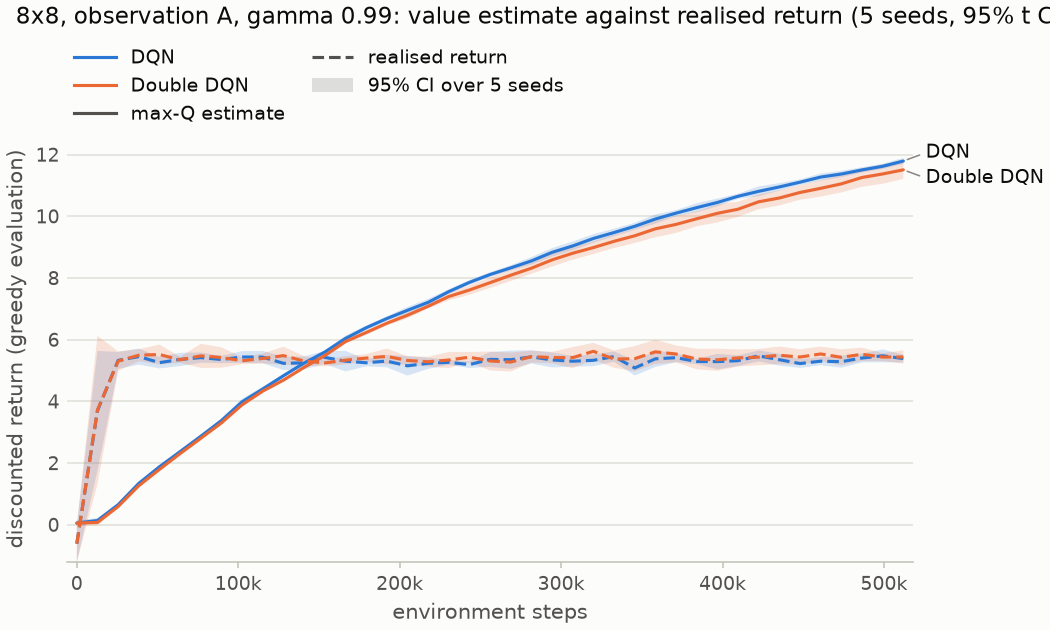

##### values_double_B8_W8

8x8, observation B8, gamma 0.99: value estimate against realised return (5 seeds, 95% t CI)

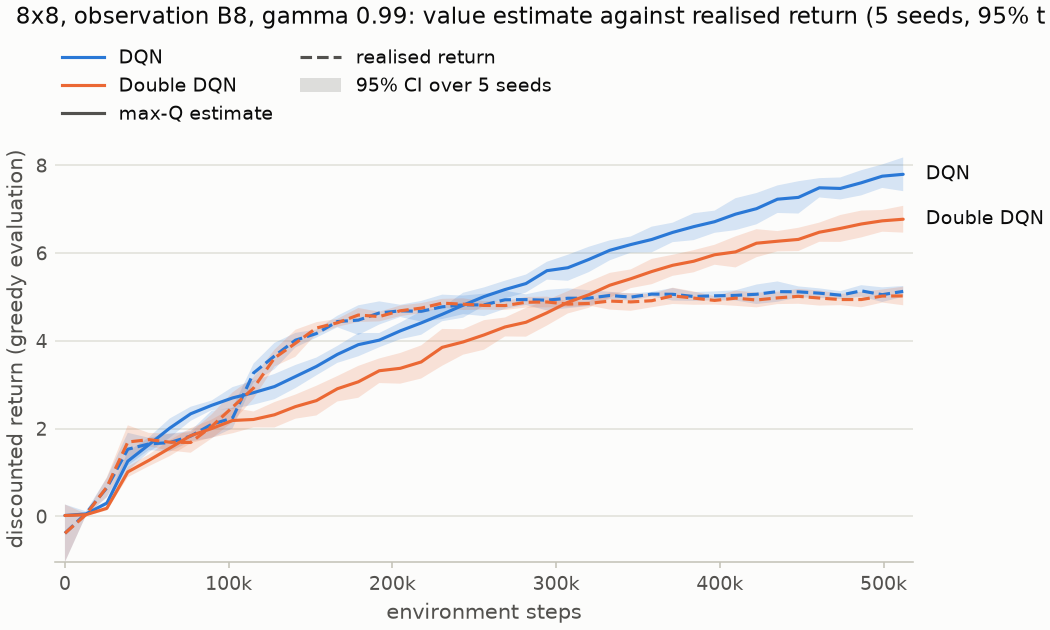

##### reward_A_W8_gamma09

8x8, observation A, gamma 0.9: reward design (5 seeds, 95% t CI)

| label | seeds | episodes | score mean +- 95% CI | CI over | median | max | mean steps | wall | self | starve | win | last-5 evals mean +- 95% CI |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| BFS greedy | 1 | 100 | 23.07 +- 1.13 | episodes | 23.0 | 38 | 151.4 | 0.35 | 0.65 | 0.00 | 0.00 | n/a |
| R0 | 5 | 100 | 16.11 +- 0.88 | seeds | 16.0 | 35 | 104.9 | 0.21 | 0.79 | 0.00 | 0.00 | 16.07 +- 0.64 |
| R1 | 5 | 100 | 16.47 +- 0.30 | seeds | 16.0 | 32 | 108.2 | 0.21 | 0.79 | 0.00 | 0.00 | 16.40 +- 0.33 |
| R2 | 5 | 100 | 16.13 +- 0.41 | seeds | 16.0 | 33 | 104.5 | 0.16 | 0.84 | 0.00 | 0.00 | 16.35 +- 0.42 |
| R3 | 5 | 100 | 16.81 +- 1.36 | seeds | 17.0 | 35 | 110.5 | 0.20 | 0.80 | 0.00 | 0.00 | 16.65 +- 0.76 |


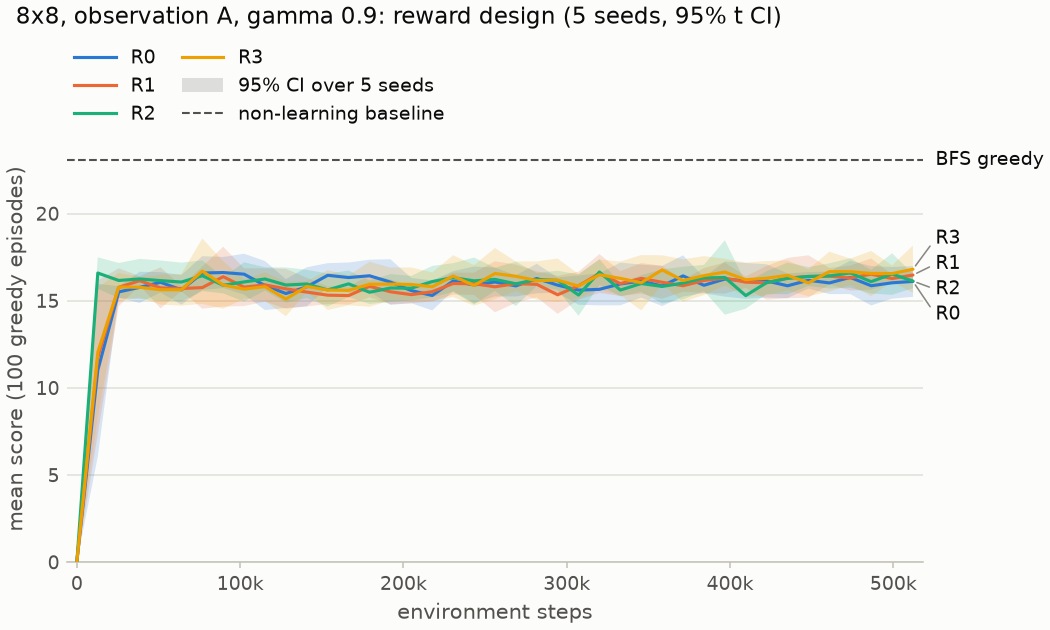

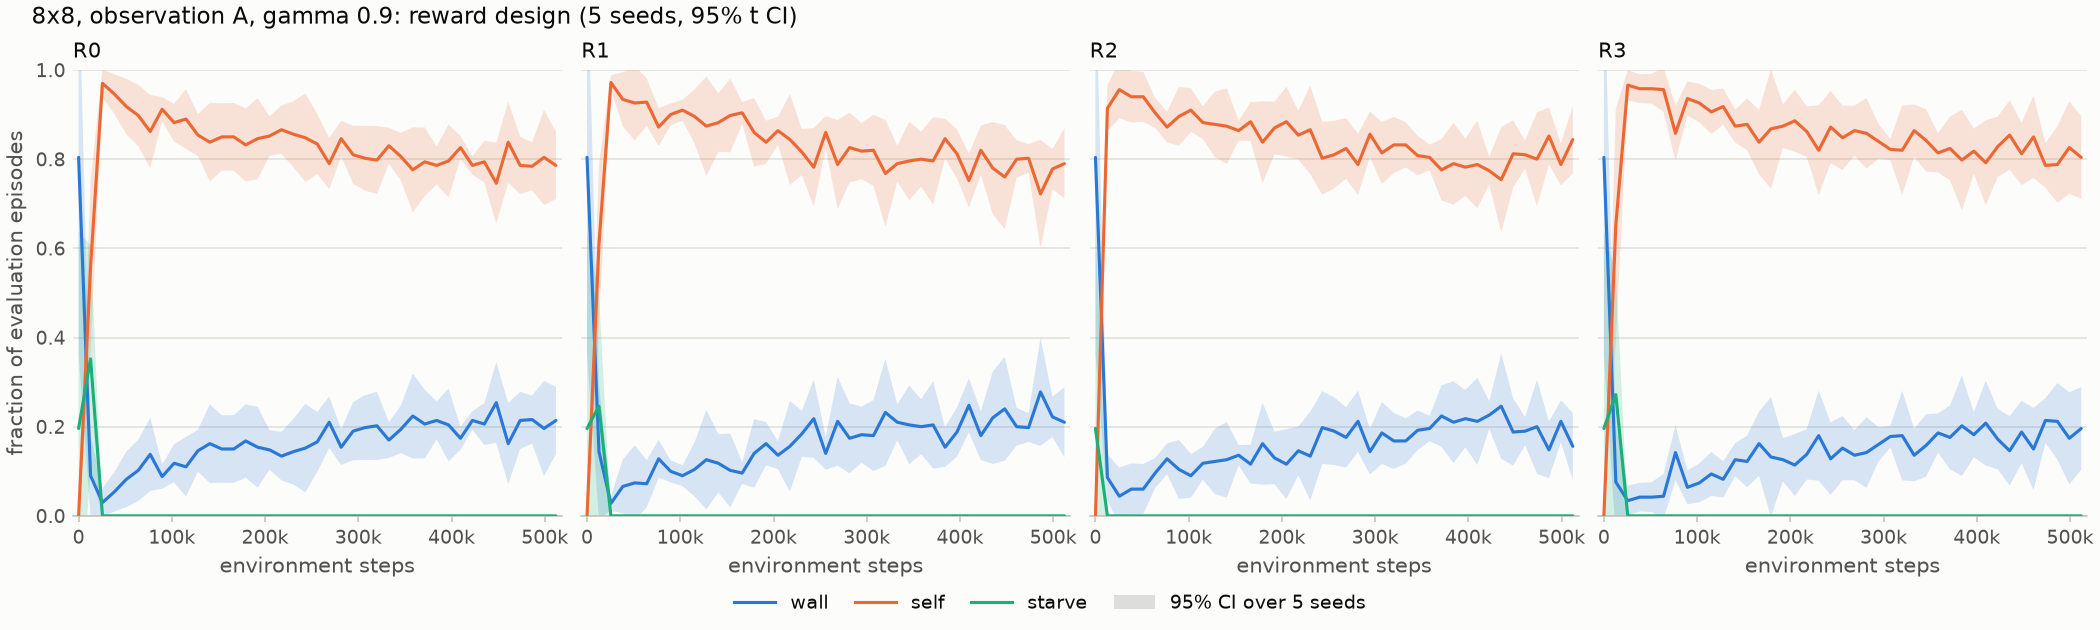

##### reward_A_W8_gamma099

8x8, observation A, gamma 0.99: reward design (5 seeds, 95% t CI)

| label | seeds | episodes | score mean +- 95% CI | CI over | median | max | mean steps | wall | self | starve | win | last-5 evals mean +- 95% CI |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| BFS greedy | 1 | 100 | 23.07 +- 1.13 | episodes | 23.0 | 38 | 151.4 | 0.35 | 0.65 | 0.00 | 0.00 | n/a |
| R0 | 5 | 100 | 15.91 +- 0.60 | seeds | 16.0 | 35 | 103.0 | 0.20 | 0.80 | 0.00 | 0.00 | 16.04 +- 0.20 |
| R1 | 5 | 100 | 16.10 +- 1.07 | seeds | 16.0 | 37 | 104.8 | 0.18 | 0.82 | 0.00 | 0.00 | 16.20 +- 0.56 |
| R2 | 5 | 100 | 15.62 +- 0.93 | seeds | 15.0 | 34 | 100.8 | 0.20 | 0.80 | 0.00 | 0.00 | 15.57 +- 0.53 |
| R3 | 5 | 100 | 16.10 +- 0.57 | seeds | 16.0 | 39 | 105.0 | 0.19 | 0.81 | 0.00 | 0.00 | 15.73 +- 0.25 |
| R3 symmetric | 5 | 100 | 15.58 +- 0.64 | seeds | 15.0 | 34 | 101.8 | 0.16 | 0.84 | 0.00 | 0.00 | 15.50 +- 0.45 |
| R3, H=1000 | 5 | 100 | 16.10 +- 0.57 | seeds | 16.0 | 39 | 105.0 | 0.19 | 0.81 | 0.00 | 0.00 | 15.73 +- 0.25 |


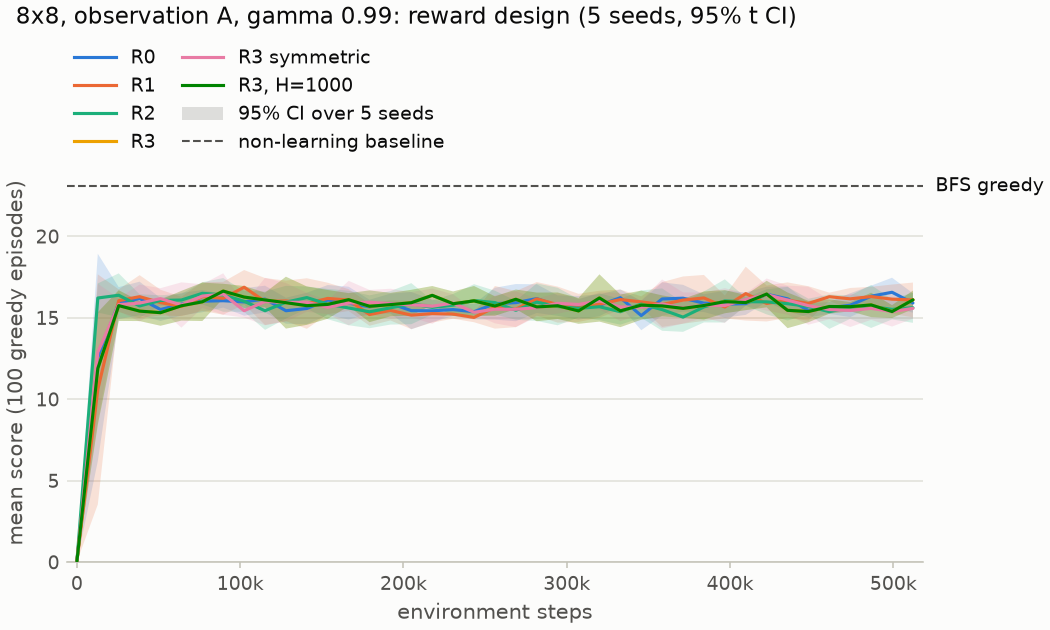

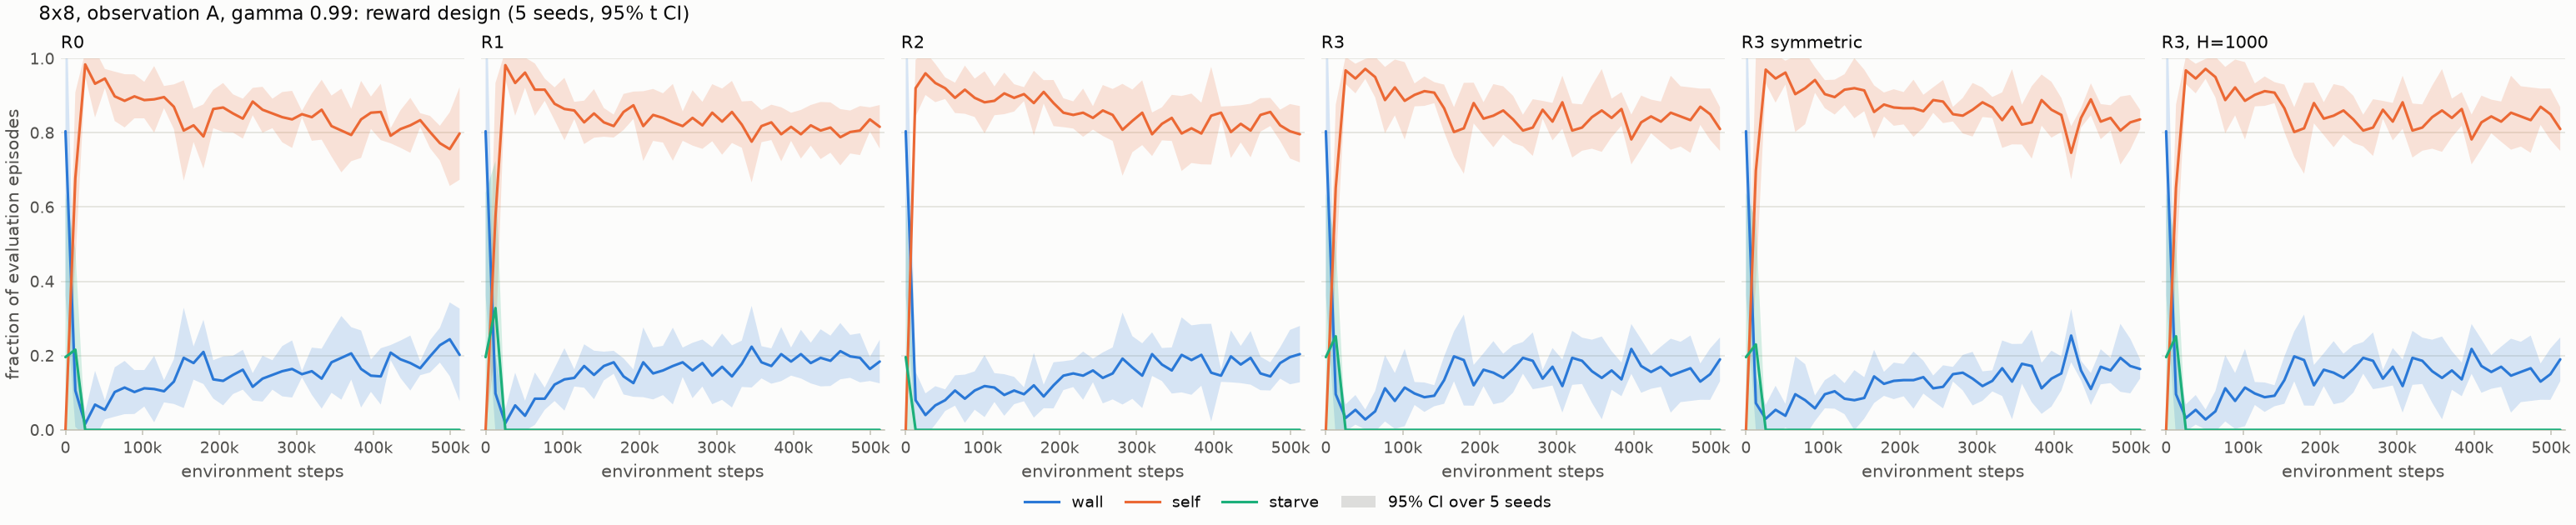

##### reward_B8_W8_gamma09

8x8, observation B8, gamma 0.9: reward design (5 seeds, 95% t CI)

| label | seeds | episodes | score mean +- 95% CI | CI over | median | max | mean steps | wall | self | starve | win | last-5 evals mean +- 95% CI |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| BFS greedy | 1 | 100 | 23.07 +- 1.13 | episodes | 23.0 | 38 | 151.4 | 0.35 | 0.65 | 0.00 | 0.00 | n/a |
| R0 | 5 | 100 | 17.81 +- 0.90 | seeds | 18.0 | 32 | 131.4 | 0.05 | 0.95 | 0.00 | 0.00 | 17.63 +- 0.28 |
| R1 | 5 | 100 | 17.56 +- 0.46 | seeds | 18.0 | 34 | 128.5 | 0.06 | 0.94 | 0.00 | 0.00 | 17.69 +- 0.26 |
| R2 | 5 | 100 | 17.12 +- 0.62 | seeds | 17.0 | 29 | 124.4 | 0.06 | 0.94 | 0.00 | 0.00 | 17.16 +- 0.49 |
| R3 | 5 | 100 | 18.08 +- 0.89 | seeds | 18.0 | 29 | 134.0 | 0.06 | 0.94 | 0.00 | 0.00 | 18.08 +- 0.57 |


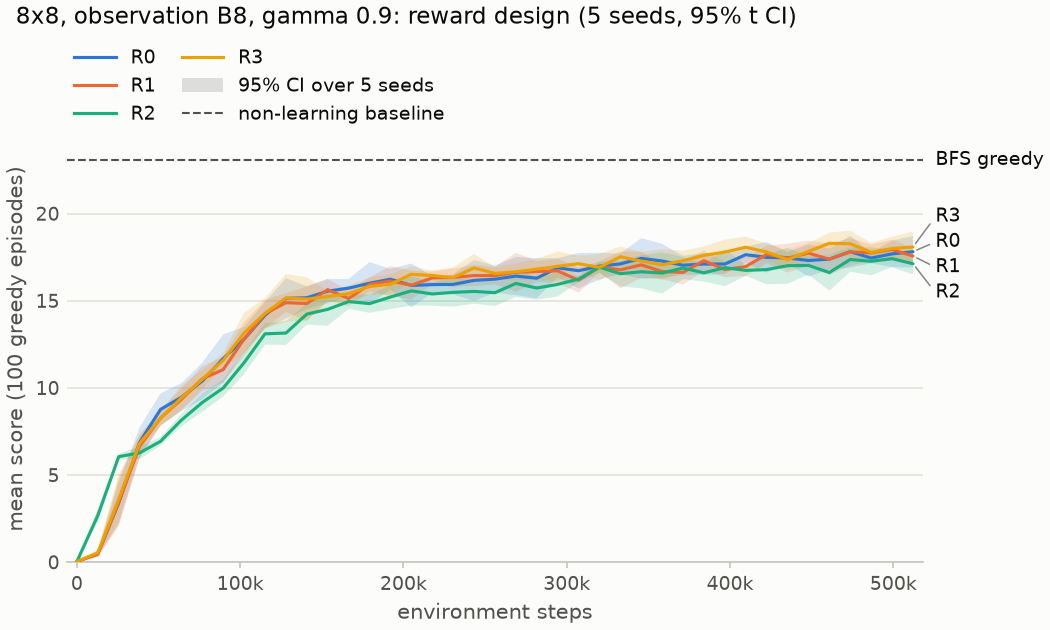

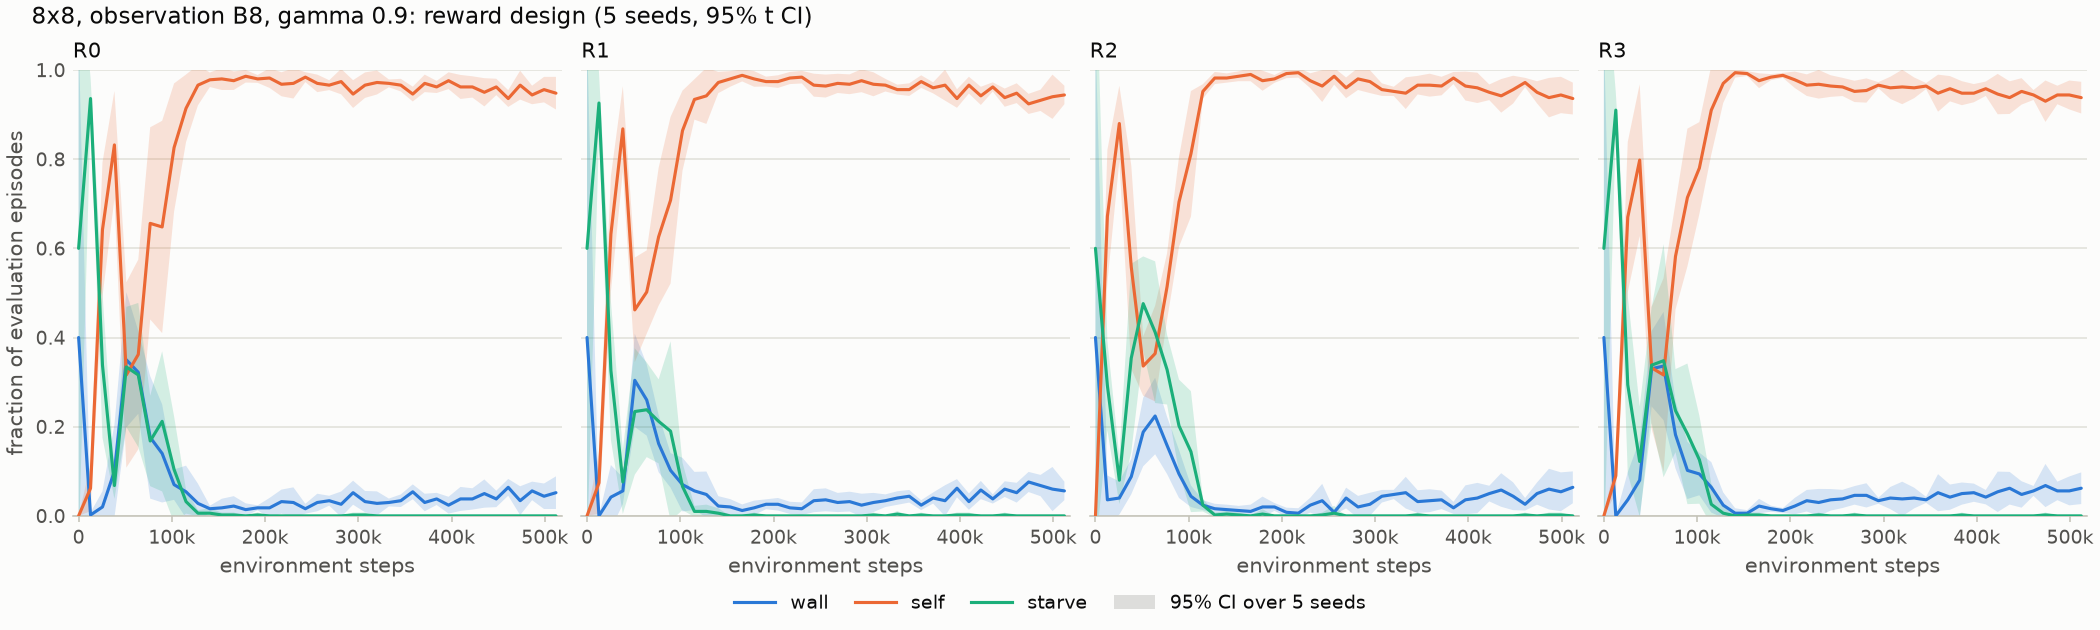

##### reward_B8_W8_gamma099

8x8, observation B8, gamma 0.99: reward design (5 seeds, 95% t CI)

| label | seeds | episodes | score mean +- 95% CI | CI over | median | max | mean steps | wall | self | starve | win | last-5 evals mean +- 95% CI |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| BFS greedy | 1 | 100 | 23.07 +- 1.13 | episodes | 23.0 | 38 | 151.4 | 0.35 | 0.65 | 0.00 | 0.00 | n/a |
| R0 | 5 | 100 | 22.72 +- 1.04 | seeds | 23.0 | 34 | 220.3 | 0.03 | 0.96 | 0.01 | 0.00 | 22.39 +- 0.55 |
| R1 | 5 | 100 | 22.72 +- 1.49 | seeds | 23.0 | 34 | 223.3 | 0.01 | 0.98 | 0.01 | 0.00 | 22.17 +- 0.95 |
| R2 | 5 | 100 | 21.59 +- 0.62 | seeds | 22.0 | 33 | 209.9 | 0.03 | 0.96 | 0.01 | 0.00 | 21.49 +- 0.35 |
| R3 | 5 | 100 | 23.52 +- 0.92 | seeds | 24.0 | 36 | 233.3 | 0.04 | 0.95 | 0.01 | 0.00 | 23.00 +- 0.73 |
| R3 symmetric | 5 | 100 | 22.88 +- 1.10 | seeds | 24.0 | 34 | 224.9 | 0.03 | 0.96 | 0.01 | 0.00 | 22.89 +- 0.21 |
| R3, H=1000 | 5 | 100 | 23.15 +- 0.77 | seeds | 24.0 | 36 | 230.0 | 0.06 | 0.94 | 0.00 | 0.00 | 23.10 +- 0.77 |


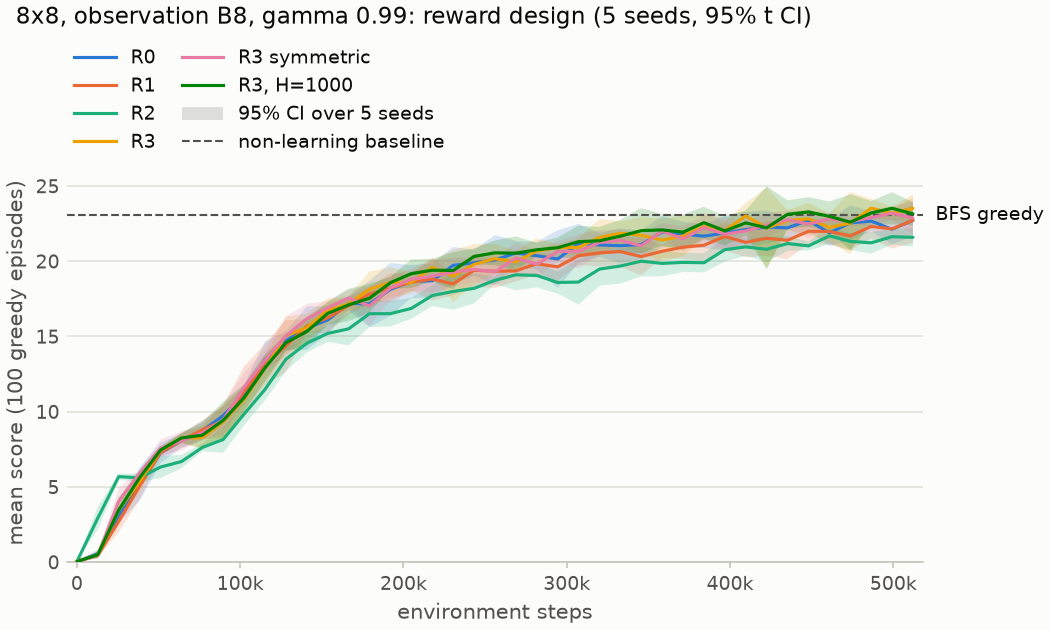

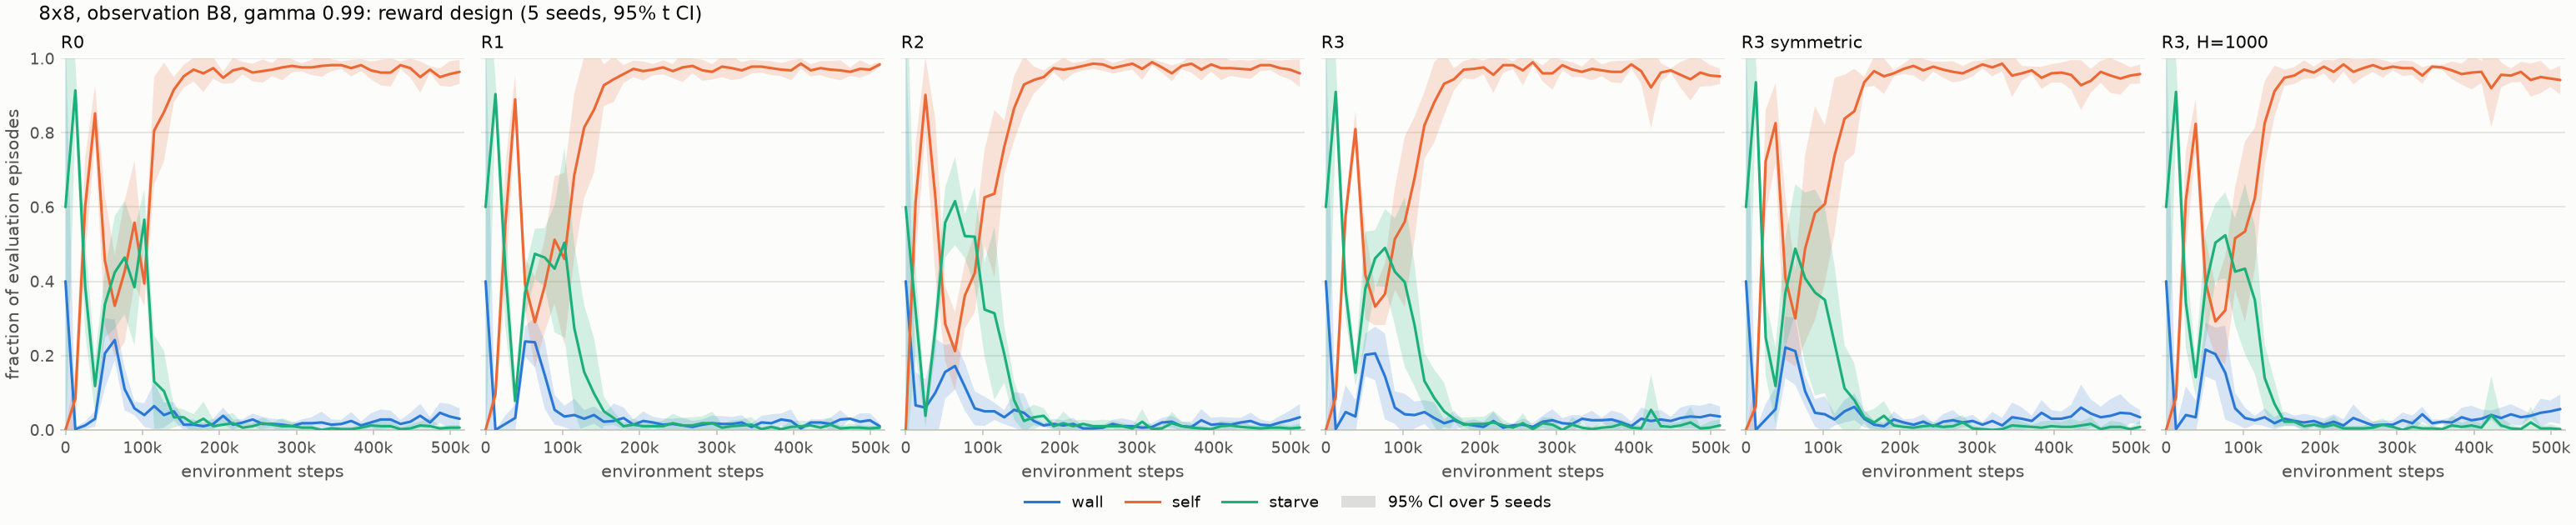

##### reward_B8_W10_gamma099

10x10, observation B8, gamma 0.99: reward design (5 seeds, 95% t CI)

| label | seeds | episodes | score mean +- 95% CI | CI over | median | max | mean steps | wall | self | starve | win | last-5 evals mean +- 95% CI |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| BFS greedy | 1 | 100 | 30.61 +- 1.60 | episodes | 31.0 | 58 | 255.8 | 0.16 | 0.84 | 0.00 | 0.00 | n/a |
| R0 | 5 | 100 | 25.72 +- 0.83 | seeds | 26.0 | 42 | 333.7 | 0.03 | 0.94 | 0.03 | 0.00 | 25.46 +- 0.40 |
| R1 | 5 | 100 | 24.72 +- 0.64 | seeds | 25.0 | 40 | 322.2 | 0.02 | 0.95 | 0.03 | 0.00 | 24.51 +- 0.77 |
| R2 | 5 | 100 | 25.27 +- 0.71 | seeds | 26.0 | 43 | 321.9 | 0.03 | 0.94 | 0.03 | 0.00 | 25.06 +- 0.81 |
| R3 | 5 | 100 | 25.76 +- 0.67 | seeds | 26.0 | 37 | 324.0 | 0.04 | 0.93 | 0.02 | 0.00 | 25.80 +- 0.70 |


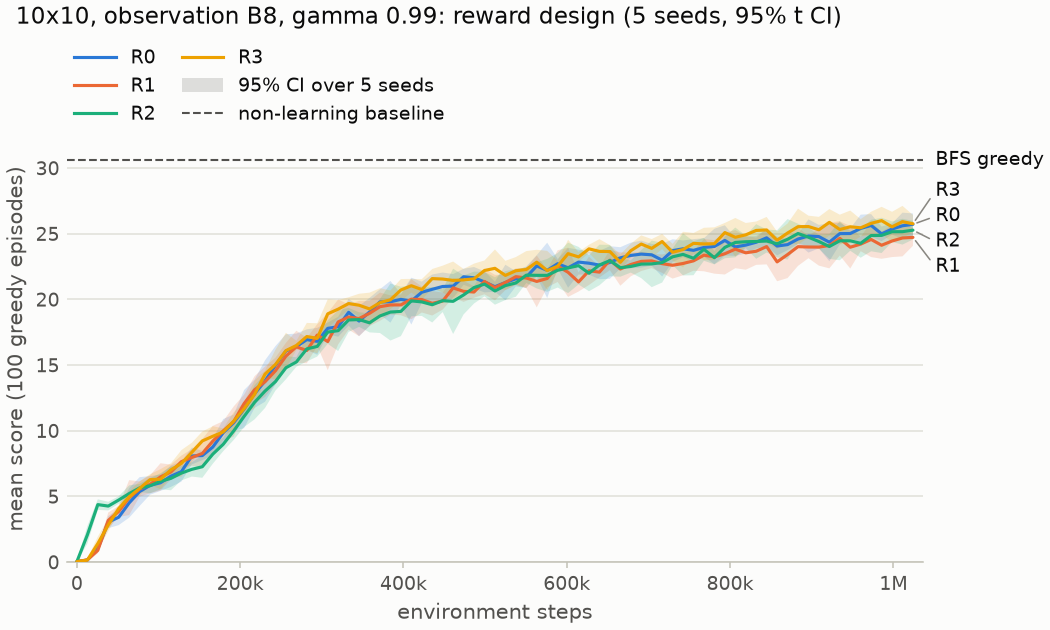

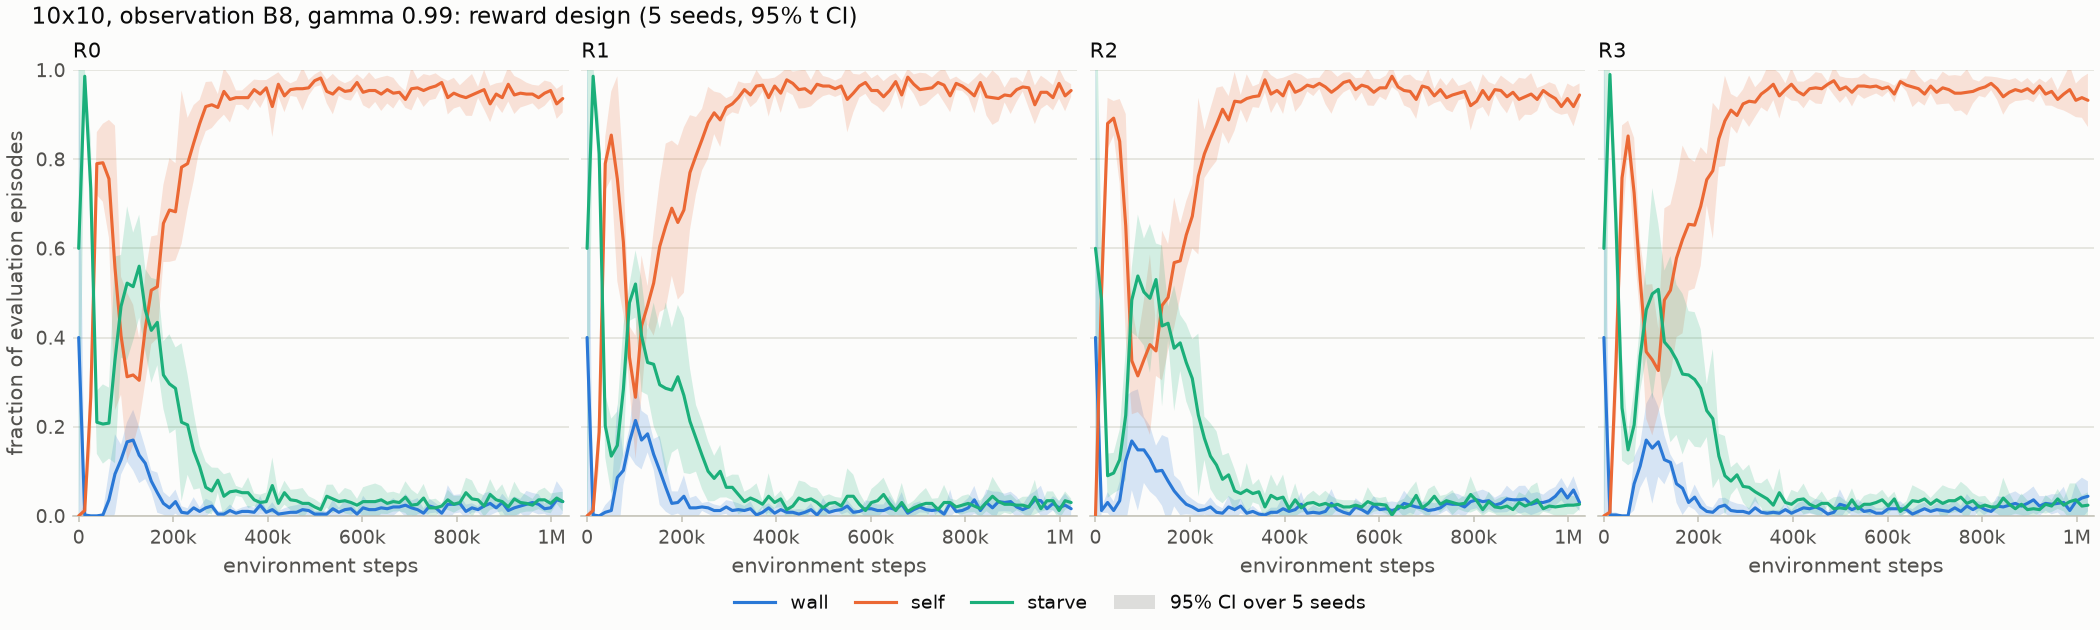

##### probe_W8

8x8, observation B8, gamma 0.99: the reward-hacking probe (5 seeds, 95% t CI)

| label | seeds | episodes | score mean +- 95% CI | CI over | median | max | mean steps | wall | self | starve | win | last-5 evals mean +- 95% CI |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| BFS greedy | 1 | 100 | 23.07 +- 1.13 | episodes | 23.0 | 38 | 151.4 | 0.35 | 0.65 | 0.00 | 0.00 | n/a |
| R0 | 5 | 100 | 22.72 +- 1.04 | seeds | 23.0 | 34 | 220.3 | 0.03 | 0.96 | 0.01 | 0.00 | 22.39 +- 0.55 |
| R3 (closer 0.01) | 5 | 100 | 23.52 +- 0.92 | seeds | 24.0 | 36 | 233.3 | 0.04 | 0.95 | 0.01 | 0.00 | 23.00 +- 0.73 |
| R3 (closer 0.1) | 5 | 100 | 24.44 +- 1.07 | seeds | 25.0 | 37 | 237.0 | 0.04 | 0.96 | 0.01 | 0.00 | 24.10 +- 0.57 |


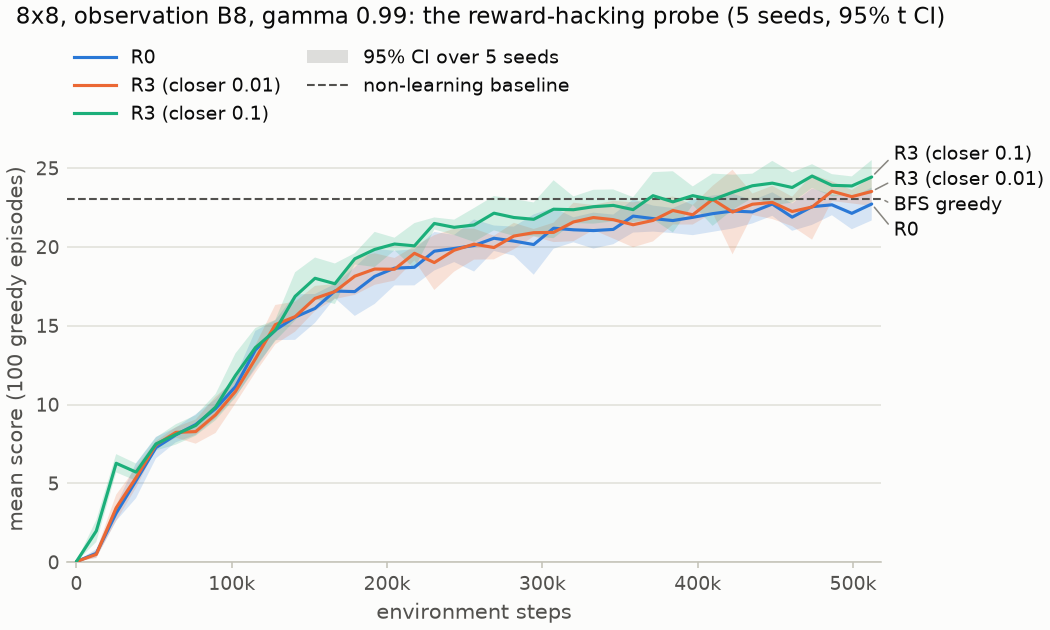

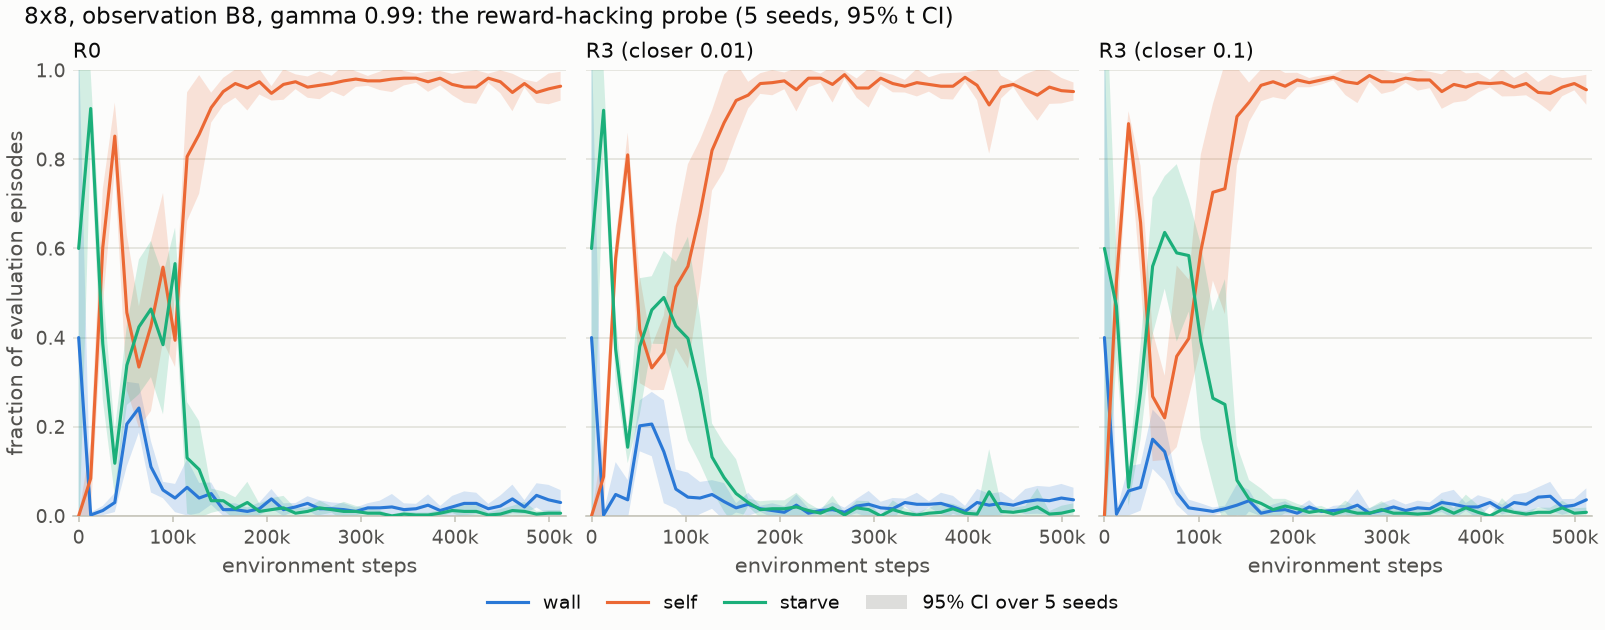

##### summary_W8

8x8: every configuration

| label | seeds | episodes | score mean +- 95% CI | CI over | median | max | mean steps | wall | self | starve | win | last-5 evals mean +- 95% CI |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| random | 1 | 100 | 0.23 +- 0.10 | episodes | 0.0 | 2 | 13.2 | 0.98 | 0.02 | 0.00 | 0.00 | n/a |
| BFS greedy | 1 | 100 | 23.07 +- 1.13 | episodes | 23.0 | 38 | 151.4 | 0.35 | 0.65 | 0.00 | 0.00 | n/a |
| Hamiltonian | 1 | 100 | 61.00 +- 0.00 | episodes | 61.0 | 61 | 985.9 | 0.00 | 0.00 | 0.00 | 1.00 | n/a |
| tabular Q | 5 | 100 | 15.67 +- 0.87 | seeds | 15.5 | 34 | 102.0 | 0.19 | 0.81 | 0.00 | 0.00 | 15.67 +- 0.40 |
| tabular Q, gamma 0 | 5 | 100 | 16.07 +- 0.10 | seeds | 16.0 | 27 | 151.5 | 0.07 | 0.93 | 0.00 | 0.00 | 16.07 +- 0.10 |
| A (MLP) | 5 | 100 | 16.11 +- 0.88 | seeds | 16.0 | 35 | 104.9 | 0.21 | 0.79 | 0.00 | 0.00 | 16.07 +- 0.64 |
| B8 (CNN) | 5 | 100 | 17.81 +- 0.90 | seeds | 18.0 | 32 | 131.4 | 0.05 | 0.95 | 0.00 | 0.00 | 17.63 +- 0.28 |
| B3 (CNN) | 5 | 100 | 13.54 +- 0.61 | seeds | 14.0 | 26 | 100.6 | 0.18 | 0.82 | 0.01 | 0.00 | 13.48 +- 0.36 |
| B7 (CNN) | 5 | 100 | 18.18 +- 0.85 | seeds | 18.0 | 30 | 135.1 | 0.08 | 0.92 | 0.00 | 0.00 | 17.93 +- 0.81 |
| A, gamma 0.99 | 5 | 100 | 15.91 +- 0.60 | seeds | 16.0 | 35 | 103.0 | 0.20 | 0.80 | 0.00 | 0.00 | 16.04 +- 0.20 |
| B8, gamma 0.99 | 5 | 100 | 22.72 +- 1.04 | seeds | 23.0 | 34 | 220.3 | 0.03 | 0.96 | 0.01 | 0.00 | 22.39 +- 0.55 |
| A, no replay | 5 | 100 | 15.39 +- 0.80 | seeds | 15.0 | 35 | 99.2 | 0.01 | 0.99 | 0.00 | 0.00 | 15.68 +- 0.71 |
| A, no replay, target 31 | 5 | 100 | 15.54 +- 0.68 | seeds | 15.0 | 31 | 100.0 | 0.02 | 0.98 | 0.00 | 0.00 | 15.24 +- 0.49 |
| A, no target | 5 | 100 | 16.61 +- 1.04 | seeds | 16.0 | 33 | 110.5 | 0.26 | 0.74 | 0.00 | 0.00 | 16.59 +- 0.60 |
| A, no replay, no target | 5 | 100 | 15.43 +- 0.81 | seeds | 15.0 | 31 | 100.0 | 0.01 | 0.99 | 0.00 | 0.00 | 15.43 +- 0.47 |
| B8, no replay | 5 | 100 | 8.55 +- 3.09 | seeds | 9.0 | 26 | 126.9 | 0.00 | 0.58 | 0.42 | 0.00 | 8.38 +- 3.32 |
| B8, no replay, target 31 | 5 | 100 | 14.03 +- 1.39 | seeds | 14.0 | 28 | 100.5 | 0.00 | 0.98 | 0.02 | 0.00 | 13.98 +- 0.77 |
| B8, no target | 5 | 100 | 18.01 +- 0.67 | seeds | 18.0 | 30 | 132.3 | 0.06 | 0.94 | 0.00 | 0.00 | 18.16 +- 0.63 |
| B8, no replay, no target | 5 | 100 | 13.90 +- 0.84 | seeds | 14.0 | 27 | 99.2 | 0.01 | 0.99 | 0.01 | 0.00 | 13.70 +- 0.65 |
| A, G=1 | 5 | 100 | 15.02 +- 0.31 | seeds | 15.0 | 36 | 96.7 | 0.02 | 0.98 | 0.00 | 0.00 | 15.38 +- 0.25 |
| A, G=4 | 5 | 100 | 15.39 +- 0.89 | seeds | 15.0 | 31 | 99.7 | 0.11 | 0.89 | 0.00 | 0.00 | 15.55 +- 0.64 |
| A, G=8, batch 1024 | 5 | 100 | 16.00 +- 1.40 | seeds | 16.0 | 38 | 105.1 | 0.17 | 0.83 | 0.00 | 0.00 | 16.02 +- 0.76 |
| B8, G=1 | 5 | 100 | 13.73 +- 3.38 | seeds | 14.0 | 30 | 134.1 | 0.00 | 0.88 | 0.12 | 0.00 | 11.83 +- 2.15 |
| B8, G=1, target 31 | 5 | 100 | 16.60 +- 0.82 | seeds | 17.0 | 30 | 119.0 | 0.00 | 0.99 | 0.00 | 0.00 | 16.11 +- 0.65 |
| A, hidden 16 | 5 | 100 | 15.60 +- 1.23 | seeds | 15.0 | 36 | 101.7 | 0.01 | 0.99 | 0.00 | 0.00 | 15.79 +- 0.71 |
| A, linear | 5 | 100 | 3.04 +- 5.30 | seeds | 1.0 | 26 | 119.9 | 0.13 | 0.11 | 0.76 | 0.00 | 2.88 +- 4.38 |
| A, Double | 5 | 100 | 17.21 +- 0.59 | seeds | 17.0 | 36 | 114.3 | 0.31 | 0.69 | 0.00 | 0.00 | 17.14 +- 0.51 |
| A, Dueling | 5 | 100 | 15.45 +- 0.87 | seeds | 15.0 | 33 | 100.9 | 0.20 | 0.80 | 0.00 | 0.00 | 15.66 +- 0.42 |
| A, PER | 5 | 100 | 15.84 +- 0.78 | seeds | 15.0 | 35 | 103.9 | 0.23 | 0.77 | 0.00 | 0.00 | 15.93 +- 0.69 |
| A, gamma 0.99, Double | 5 | 100 | 16.37 +- 0.80 | seeds | 16.0 | 37 | 107.3 | 0.20 | 0.80 | 0.00 | 0.00 | 16.61 +- 0.41 |
| B8, Double | 5 | 100 | 17.69 +- 0.56 | seeds | 18.0 | 29 | 131.1 | 0.05 | 0.95 | 0.00 | 0.00 | 17.57 +- 0.30 |
| B8, Dueling | 5 | 100 | 18.09 +- 0.93 | seeds | 18.0 | 30 | 132.3 | 0.02 | 0.98 | 0.00 | 0.00 | 17.83 +- 0.50 |
| B8, PER | 5 | 100 | 17.14 +- 1.08 | seeds | 18.0 | 35 | 123.6 | 0.04 | 0.95 | 0.00 | 0.00 | 17.06 +- 0.26 |
| B8, gamma 0.99, Double | 5 | 100 | 22.38 +- 1.10 | seeds | 23.0 | 34 | 222.7 | 0.03 | 0.96 | 0.01 | 0.00 | 21.90 +- 0.50 |
| A, R1 | 5 | 100 | 16.47 +- 0.30 | seeds | 16.0 | 32 | 108.2 | 0.21 | 0.79 | 0.00 | 0.00 | 16.40 +- 0.33 |
| A, R2 | 5 | 100 | 16.13 +- 0.41 | seeds | 16.0 | 33 | 104.5 | 0.16 | 0.84 | 0.00 | 0.00 | 16.35 +- 0.42 |
| A, R3 | 5 | 100 | 16.81 +- 1.36 | seeds | 17.0 | 35 | 110.5 | 0.20 | 0.80 | 0.00 | 0.00 | 16.65 +- 0.76 |
| A, gamma 0.99, R1 | 5 | 100 | 16.10 +- 1.07 | seeds | 16.0 | 37 | 104.8 | 0.18 | 0.82 | 0.00 | 0.00 | 16.20 +- 0.56 |
| A, gamma 0.99, R2 | 5 | 100 | 15.62 +- 0.93 | seeds | 15.0 | 34 | 100.8 | 0.20 | 0.80 | 0.00 | 0.00 | 15.57 +- 0.53 |
| A, gamma 0.99, R3 | 5 | 100 | 16.10 +- 0.57 | seeds | 16.0 | 39 | 105.0 | 0.19 | 0.81 | 0.00 | 0.00 | 15.73 +- 0.25 |
| A, gamma 0.99, R3 symmetric | 5 | 100 | 15.58 +- 0.64 | seeds | 15.0 | 34 | 101.8 | 0.16 | 0.84 | 0.00 | 0.00 | 15.50 +- 0.45 |
| A, gamma 0.99, R3, H=1000 | 5 | 100 | 16.10 +- 0.57 | seeds | 16.0 | 39 | 105.0 | 0.19 | 0.81 | 0.00 | 0.00 | 15.73 +- 0.25 |
| B8, R1 | 5 | 100 | 17.56 +- 0.46 | seeds | 18.0 | 34 | 128.5 | 0.06 | 0.94 | 0.00 | 0.00 | 17.69 +- 0.26 |
| B8, R2 | 5 | 100 | 17.12 +- 0.62 | seeds | 17.0 | 29 | 124.4 | 0.06 | 0.94 | 0.00 | 0.00 | 17.16 +- 0.49 |
| B8, R3 | 5 | 100 | 18.08 +- 0.89 | seeds | 18.0 | 29 | 134.0 | 0.06 | 0.94 | 0.00 | 0.00 | 18.08 +- 0.57 |
| B8, gamma 0.99, R1 | 5 | 100 | 22.72 +- 1.49 | seeds | 23.0 | 34 | 223.3 | 0.01 | 0.98 | 0.01 | 0.00 | 22.17 +- 0.95 |
| B8, gamma 0.99, R2 | 5 | 100 | 21.59 +- 0.62 | seeds | 22.0 | 33 | 209.9 | 0.03 | 0.96 | 0.01 | 0.00 | 21.49 +- 0.35 |
| B8, gamma 0.99, R3 | 5 | 100 | 23.52 +- 0.92 | seeds | 24.0 | 36 | 233.3 | 0.04 | 0.95 | 0.01 | 0.00 | 23.00 +- 0.73 |
| B8, gamma 0.99, R3 symmetric | 5 | 100 | 22.88 +- 1.10 | seeds | 24.0 | 34 | 224.9 | 0.03 | 0.96 | 0.01 | 0.00 | 22.89 +- 0.21 |
| B8, gamma 0.99, R3, H=1000 | 5 | 100 | 23.15 +- 0.77 | seeds | 24.0 | 36 | 230.0 | 0.06 | 0.94 | 0.00 | 0.00 | 23.10 +- 0.77 |
| B8, gamma 0.99, R3, closer 0.1 | 5 | 100 | 24.44 +- 1.07 | seeds | 25.0 | 37 | 237.0 | 0.04 | 0.96 | 0.01 | 0.00 | 24.10 +- 0.57 |


##### summary_W10

10x10: every configuration

| label | seeds | episodes | score mean +- 95% CI | CI over | median | max | mean steps | wall | self | starve | win | last-5 evals mean +- 95% CI |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| random | 1 | 100 | 0.18 +- 0.08 | episodes | 0.0 | 2 | 23.0 | 0.98 | 0.01 | 0.01 | 0.00 | n/a |
| BFS greedy | 1 | 100 | 30.61 +- 1.60 | episodes | 31.0 | 58 | 255.8 | 0.16 | 0.84 | 0.00 | 0.00 | n/a |
| Hamiltonian | 1 | 100 | 97.00 +- 0.00 | episodes | 97.0 | 97 | 2409.7 | 0.00 | 0.00 | 0.00 | 1.00 | n/a |
| tabular Q | 5 | 100 | 18.51 +- 1.10 | seeds | 18.0 | 40 | 150.6 | 0.10 | 0.90 | 0.00 | 0.00 | 18.14 +- 0.29 |
| tabular Q, gamma 0 | 5 | 100 | 19.69 +- 0.00 | seeds | 20.0 | 34 | 239.2 | 0.04 | 0.96 | 0.00 | 0.00 | 19.69 +- 0.00 |
| A (MLP) | 5 | 100 | 20.29 +- 1.55 | seeds | 20.0 | 41 | 167.8 | 0.16 | 0.84 | 0.00 | 0.00 | 20.44 +- 1.41 |
| B8 (CNN) | 5 | 100 | 20.69 +- 0.52 | seeds | 21.0 | 35 | 187.6 | 0.07 | 0.93 | 0.00 | 0.00 | 20.85 +- 0.59 |
| B3 (CNN) | 5 | 100 | 16.12 +- 0.25 | seeds | 16.0 | 32 | 150.4 | 0.16 | 0.84 | 0.00 | 0.00 | 15.81 +- 0.33 |
| B7 (CNN) | 5 | 100 | 21.84 +- 0.74 | seeds | 22.0 | 38 | 203.5 | 0.07 | 0.93 | 0.00 | 0.00 | 21.49 +- 0.43 |
| B8, gamma 0.99 | 5 | 100 | 25.72 +- 0.83 | seeds | 26.0 | 42 | 333.7 | 0.03 | 0.94 | 0.03 | 0.00 | 25.46 +- 0.40 |
| A, no replay, target 31 | 5 | 100 | 18.22 +- 0.47 | seeds | 18.0 | 39 | 146.0 | 0.02 | 0.98 | 0.00 | 0.00 | 18.33 +- 0.20 |
| A, no target | 5 | 100 | 20.73 +- 1.77 | seeds | 20.0 | 46 | 173.1 | 0.16 | 0.84 | 0.00 | 0.00 | 20.56 +- 1.22 |
| B8, no replay | 5 | 100 | 16.60 +- 2.33 | seeds | 17.0 | 33 | 183.8 | 0.00 | 0.89 | 0.11 | 0.00 | 16.03 +- 2.81 |
| B8, no replay, target 31 | 5 | 100 | 21.70 +- 1.07 | seeds | 22.0 | 40 | 188.7 | 0.01 | 0.99 | 0.00 | 0.00 | 20.67 +- 0.63 |
| B8, no target | 5 | 100 | 21.03 +- 0.55 | seeds | 21.0 | 36 | 190.1 | 0.08 | 0.92 | 0.00 | 0.00 | 21.45 +- 0.40 |
| B8, G=1, target 31 | 5 | 100 | 23.03 +- 1.11 | seeds | 23.0 | 38 | 196.3 | 0.01 | 0.99 | 0.00 | 0.00 | 22.92 +- 0.78 |
| B8, gamma 0.99, R1 | 5 | 100 | 24.72 +- 0.64 | seeds | 25.0 | 40 | 322.2 | 0.02 | 0.95 | 0.03 | 0.00 | 24.51 +- 0.77 |
| B8, gamma 0.99, R2 | 5 | 100 | 25.27 +- 0.71 | seeds | 26.0 | 43 | 321.9 | 0.03 | 0.94 | 0.03 | 0.00 | 25.06 +- 0.81 |
| B8, gamma 0.99, R3 | 5 | 100 | 25.76 +- 0.67 | seeds | 26.0 | 37 | 324.0 | 0.04 | 0.93 | 0.02 | 0.00 | 25.80 +- 0.70 |


In [6]:
# Show every item of the manifest: the Markdown table and the PNG figures
with open("runs/report/manifest.json", encoding="utf-8") as f:
    manifest = json.load(f)
print("code", manifest["git"], "| last-k column:", manifest["last_k"], "|", len(manifest["items"]), "items")

for item in manifest["items"]:
    if not item["outputs"]:
        continue
    display(Markdown(f"##### {item['name']}\n\n{item.get('title') or ''}"))
    for kind, rel in item["outputs"].items():
        path = os.path.join("runs/report", rel)
        if kind == "table":
            with open(path, encoding="utf-8") as f:
                display(Markdown(f.read()))
        else:
            display(Image(filename=path))

#### 4.3 Composite figures (needs the saved behaviour analyses)

Figures 2, 9, 11 and 12 of the report: the score distributions and the death causes come from the run directories, the
heat-maps of several players on one colour scale from the saved behaviour analyses under `runs/behaviour/`.

written runs\report\figures\behaviour_heatmaps_W10.png
written runs\report\figures\behaviour_heatmaps_W8.png
written runs\report\figures\causes_B8_W8_gamma099_R0R2R3.png
written runs\report\figures\score_distributions.png


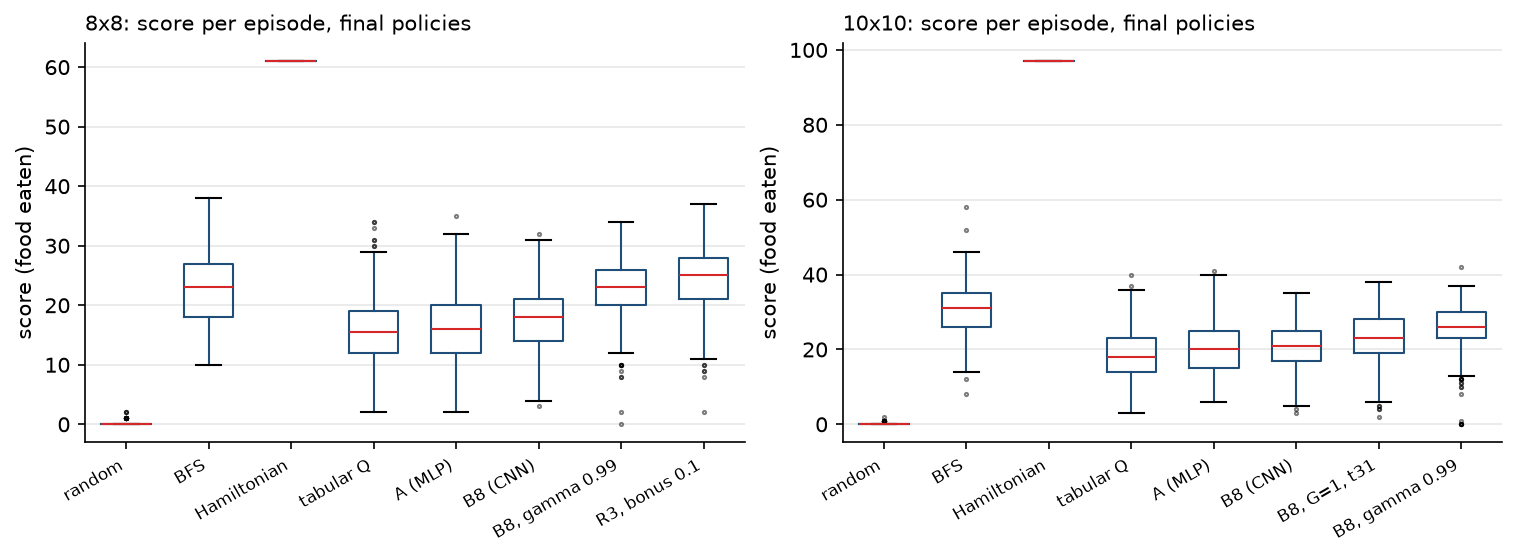

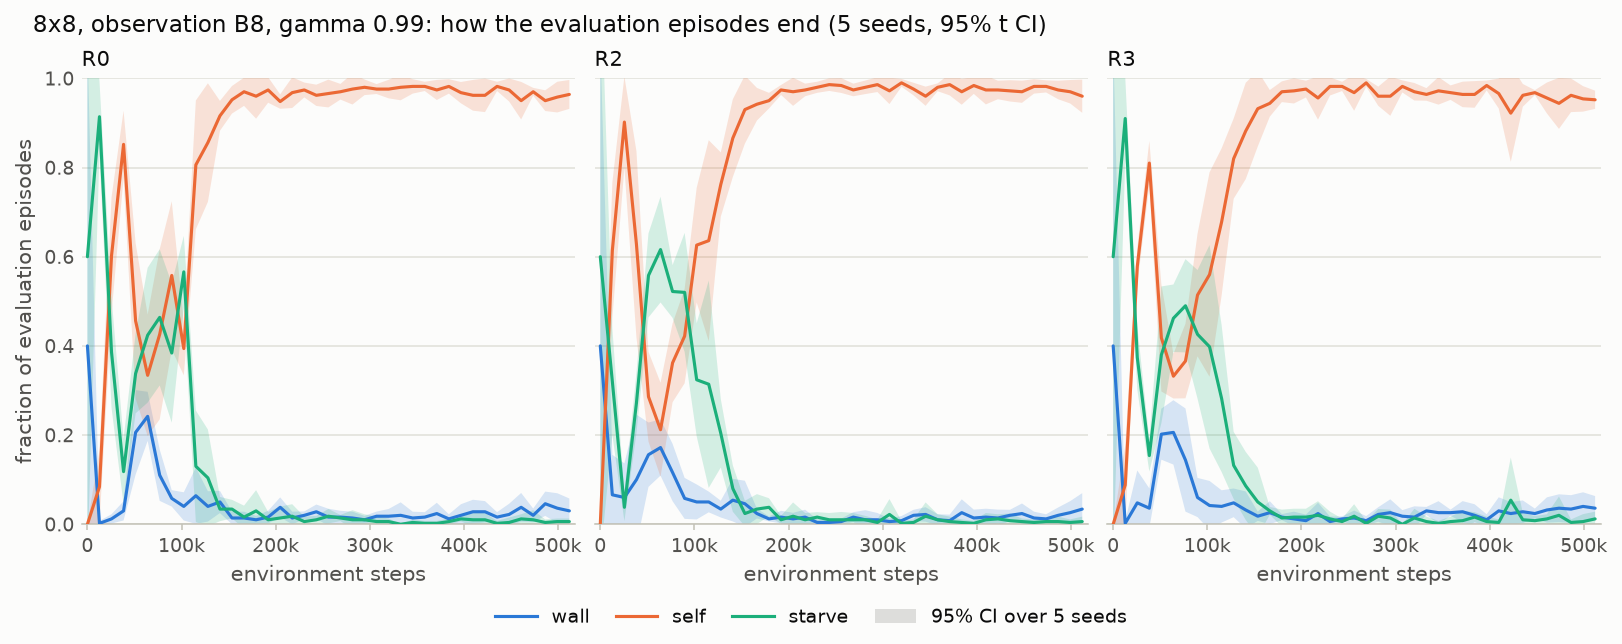

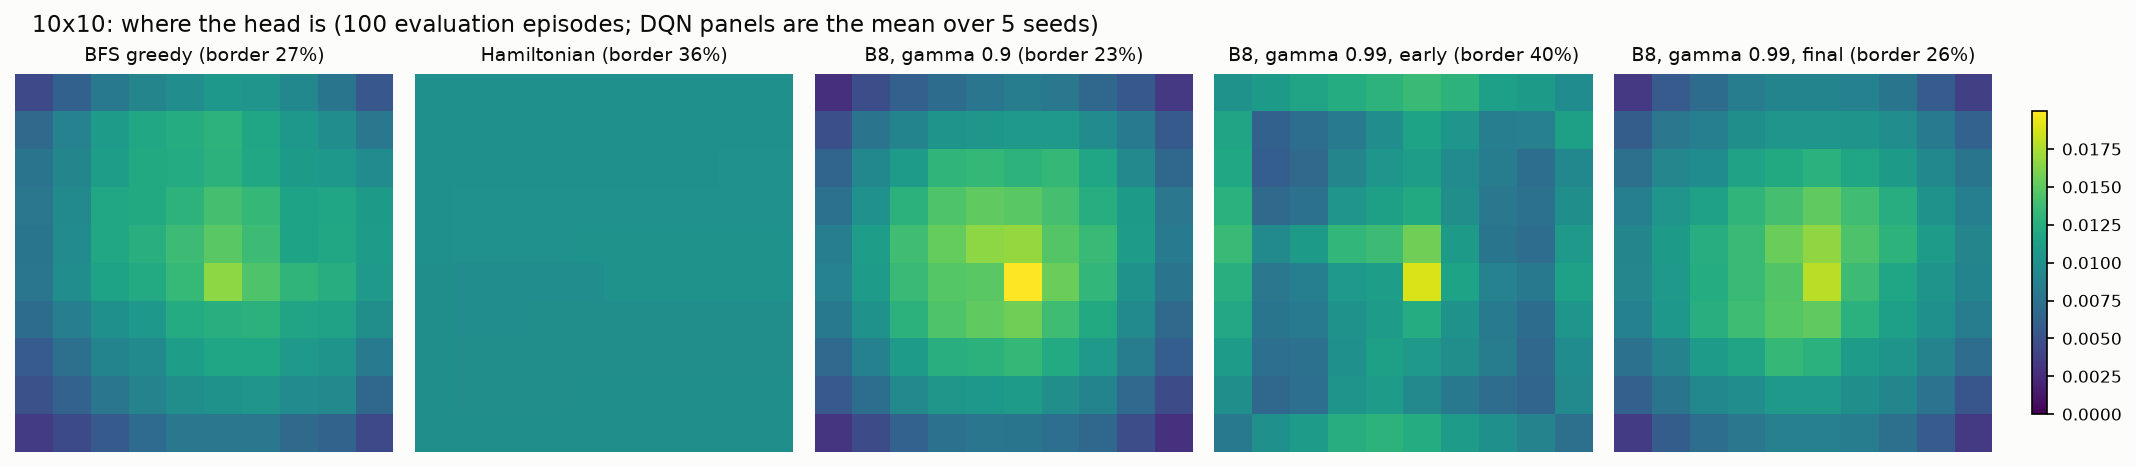

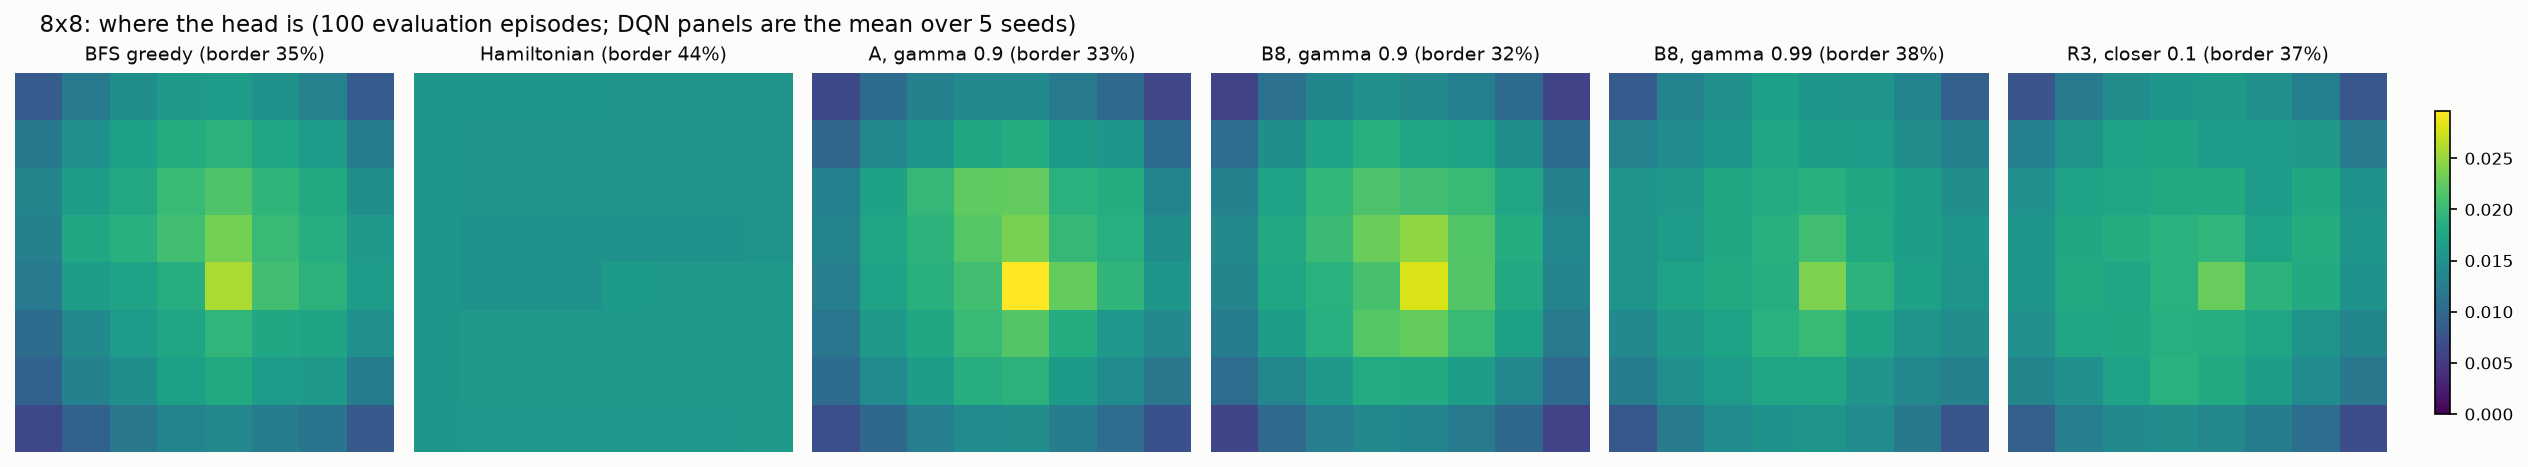

In [7]:
# Composite figures of the report; the heat-map panels need the behaviour analyses listed in scripts/report_extra_figures.py
sys.path.insert(0, "scripts")
from report_extra_figures import CAUSE_FIGURES, PANELS, SCORE_DISTRIBUTIONS

needed = sorted({name for _, _, panels in PANELS for _, name in panels})
missing = [name for name in needed if not os.path.isdir(os.path.join("runs/behaviour", name))]
if missing:
    print("behaviour analyses missing under runs/behaviour:", ", ".join(missing))
    print("export the logs with --include-behaviour, or run snake_rl.analysis.behaviour for these players first")
else:
    !{sys.executable} scripts/report_extra_figures.py --out-dir runs/report/figures
    for file_name in [p[0] for p in SCORE_DISTRIBUTIONS] + [c[0] for c in CAUSE_FIGURES] + [p[0] for p in PANELS]:
        display(Image(filename=os.path.join("runs/report/figures", file_name)))

### 5. Behaviour Analysis of One Run (needs weights)

`snake_rl.analysis.behaviour` plays 100 evaluation episodes with a trained network and writes the visit heat-map, the
loop / shaping statistics per episode and GUI-replayable recordings of the longest loops
(`python -m snake_rl.gui.app --replay <file>`). It needs a `model.pt`, which the logs zip does not carry: train a run
(`python -m snake_rl.train --config configs/dqn_B_8x8.yaml --seed 0 --set agent.gamma=0.99 --exp dqn_B8_W8_gamma099`)
or copy a run directory here.

runs\behaviour\notebook\summary.json


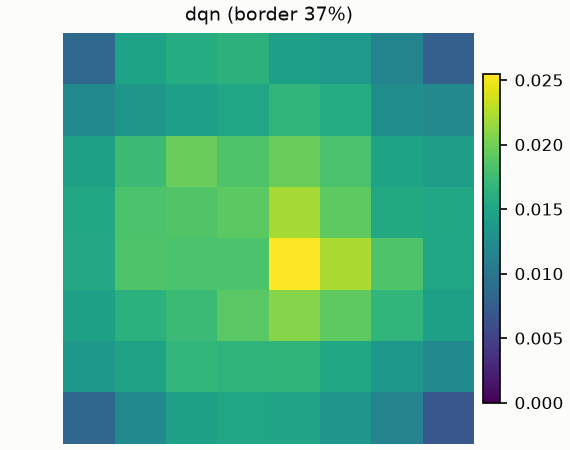

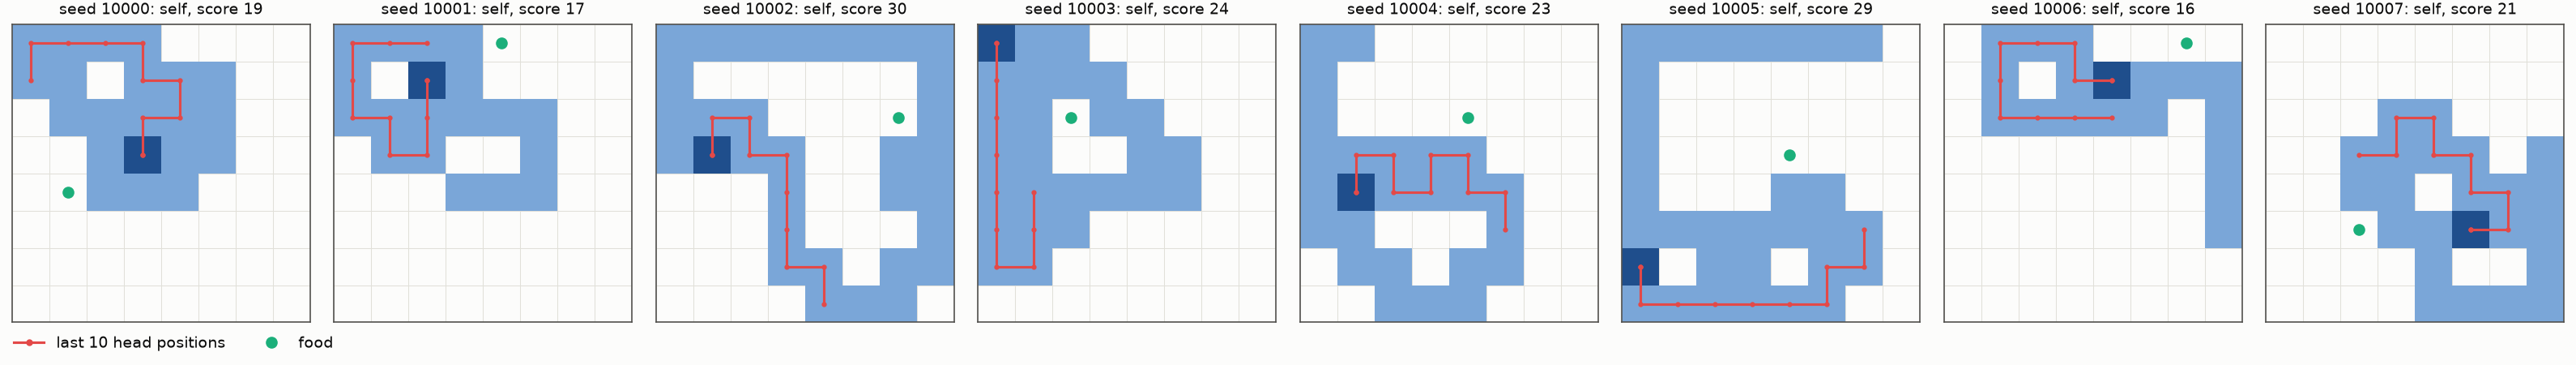

{
  "n_episodes": 100,
  "score_mean": 22.13,
  "steps_mean": 203.23,
  "length_mean": 25.13,
  "frac_wall": 0.0,
  "frac_self": 1.0,
  "frac_starve": 0.0,
  "frac_win": 0.0,
  "frac_truncated": 0.0,
  "frac_cut": 0.0,
  "tail_without_food_mean": 10.18,
  "loop_fraction": 0.0,
  "loop_steps_mean": 0.92,
  "shaping_reward_mean": 0.0,
  "border_fraction_mean": 0.3626421806178402,
  "q_max_mean": 8.440579130040605,
  "player": "dqn",
  "env": {
    "W": 8,
    "action_mode": "relative",
    "starve_limit": null,
    "obs": {
      "kind": "B",
      "age_plane": true,
      "heading_planes": true
    },
    "reward": {
      "variant": "R0",
      "food": 1.0,
      "death": -1.0,
      "step_penalty": 0.01,
      "gamma": 0.99,
      "closer": 0.01,
      "farther": 0.0
    }
  },
  "seed": 10000,
  "max_steps": null,
  "git": "96abe54+dirty",
  "hacking_cases": [],
  "checkpoint": 512000,
  "source": "runs/dqn_B8_W8_gamma099/0"
}


In [8]:
# Behaviour analysis of one run: 100 greedy episodes, heat-map, loop statistics and recordings of the longest loops
RUN_DIR = "runs/dqn_B8_W8_gamma099/0"   # any run directory with model.pt
OUT_DIR = "runs/behaviour/notebook"

if os.path.exists(os.path.join(RUN_DIR, "model.pt")):
    !{sys.executable} -m snake_rl.analysis.behaviour --player {RUN_DIR} --checkpoint final --device {DEVICE} --out-dir {OUT_DIR}
    display(Image(filename=os.path.join(OUT_DIR, "heatmap.png")))
    display(Image(filename=os.path.join(OUT_DIR, "last_steps.png")))
    with open(os.path.join(OUT_DIR, "summary.json"), encoding="utf-8") as f:
        print(json.dumps(json.load(f), indent=2)[:2000])
else:
    print("no weights at", RUN_DIR, "- the logs zip carries none; see the note above")